# **TRABAJO PRÁCTICO N° 2 - Mineria de Datos**
---
2do Cuatrimestre - Año 2026

**Integrantes:**

* Bartomioli, Ornella
* Ruiz, Irma Carolina

**Docentes:** Flavio E. Spetale - Ramiro Gatti - Julieta López Ceratto


*Trabajo hecho en VS Code*



----





### Importaciones

In [1]:
# Manejo de datos
import numpy as np
import pandas as pd
import os

# Visualización
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns

# Preparación de datos
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Arboles de desición
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor,plot_tree, export_text,export_graphviz
from sklearn.model_selection import train_test_split

# Flujo de datos
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler

# Métricas
from sklearn.metrics import (accuracy_score, precision_score, recall_score,f1_score, confusion_matrix, mean_absolute_error,
                             mean_squared_error,classification_report,ConfusionMatrixDisplay,roc_curve, auc)


# Clasificador Bayesiano ingenuo
from sklearn.naive_bayes import GaussianNB, CategoricalNB

# Clasificador KNN
from sklearn.neighbors import KNeighborsClassifier


## PARTE A - Regresión (dataset 1000_Companies.csv)

### **Punto 1 - Preparación de datos**

#### **EDA - Limpieza y análisis de los datos.**


In [2]:
# Carga y visuaización del dataset sobre las empresas
empresas = pd.read_csv('1000_Companies.csv')
empresas.head()

,RyD_Spend,Administration,MarketingSpend,State,Profit
0,165349.20,136897.80,471784.10,New York,192261.83
1,162597.70,151377.59,443898.53,California,191792.06
2,153441.51,101145.55,407934.54,Florida,191050.39
3,144372.41,118671.85,383199.62,New York,182901.99
4,142107.34,91391.77,366168.42,Florida,166187.94


In [3]:
empresas.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   RyD_Spend       1000 non-null   float64
 1   Administration  1000 non-null   float64
 2   MarketingSpend  1000 non-null   float64
 3   State           1000 non-null   str    
 4   Profit          1000 non-null   float64
dtypes: float64(4), str(1)
memory usage: 47.4 KB


Se puede observar que el conjunto de datos no presenta datos faltantes. Asimismo, todas las variables son de tipo float, salvo State que es de tipo string.

#### Análisis de Variables:

In [4]:
empresas.describe()

,RyD_Spend,Administration,MarketingSpend,Profit
count,1000.000000,1000.000000,1000.000000,1000.000000
mean,81668.927200,122963.897612,226205.058419,119546.164656
std,46537.567891,12613.927535,91578.393542,42888.633848
min,0.000000,51283.140000,0.000000,14681.400000
25%,43084.500000,116640.684850,150969.584600,85943.198543
50%,79936.000000,122421.612150,224517.887350,117641.466300
75%,124565.500000,129139.118000,308189.808525,155577.107425
max,165349.200000,321652.140000,471784.100000,476485.430000


***RyD_Spend :***

**Media:** 81668.92 | **Mediana:** 79936.00  
Presenta una Media y una Mediana muy similar, lo que se puede asociar a una distribución aparentemente simetrica sin presencia de valores extremos.

**Rango:** 0 – 165349.20  

Su minimo en 0 sugiere que algunas empresas no realizaron inversión en investigación y desarrollo.
**Desviación estándar:** 46537.567

Indica una **variabilidad significativa**.

---
***Administration:***

**Media:** 122963.89 | **Mediana:** 122421.61  
La Media y la Mediana son similares, por lo que sugiere una **distribucion simétrica** pero con colas largas por sus valores mínimos y máximos.

**Rango:** 51283.14 – 321652.14

**Desviación estándar:**  12613.92

---
***MarketingSpend:***

**Media:** 226205.05 | **Mediana:** 224517.88  

**Rango:** 0 – 471784.10

**Desviación estándar:**  91578.39

Muy elevada, sugiere una **gran dispersión**.

---
***Profit:***

**Media:** 119546.16 | **Mediana:** 117641.46  
Con media mayor, lo que indica una **distribución asimétrica**.

**Rango:** 14681.40 – 476485.43.

Se ve la diferencia en rentabilidad de las diferentes empresas.
**Desviación estándar:** 42888.63

Alta desviacion estándar, lo que indica **alta variabilidad**.

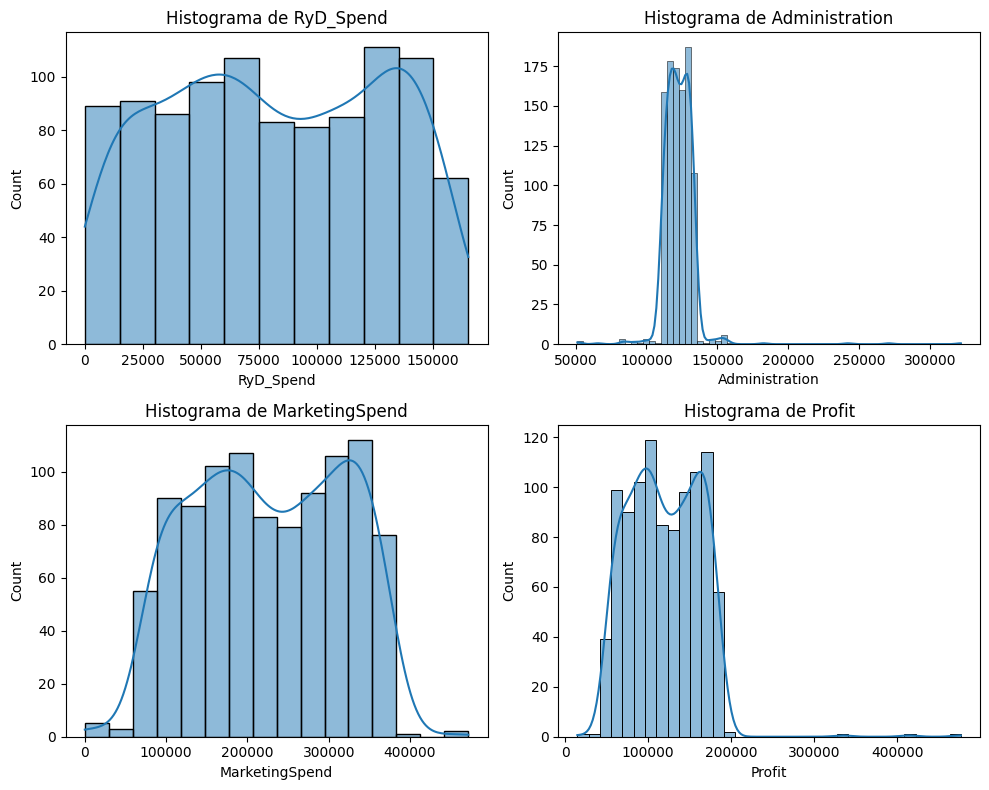

In [5]:
#verificacion de lo analizado anteriormente
cols_num = empresas.select_dtypes(include=['float'])

plt.figure(figsize=(10,8))

for i, col in enumerate(cols_num):
    plt.subplot(2, 2, i+1)
    sns.histplot(empresas[col], kde=True)
    plt.title(f"Histograma de {col}")

plt.tight_layout()
plt.show()

Se confirman las sospechas de colas extensas en Profit y en Administration, sobre todo a la derecha, cosa que ambas comparten, si bien Administration posee a ambos lados.

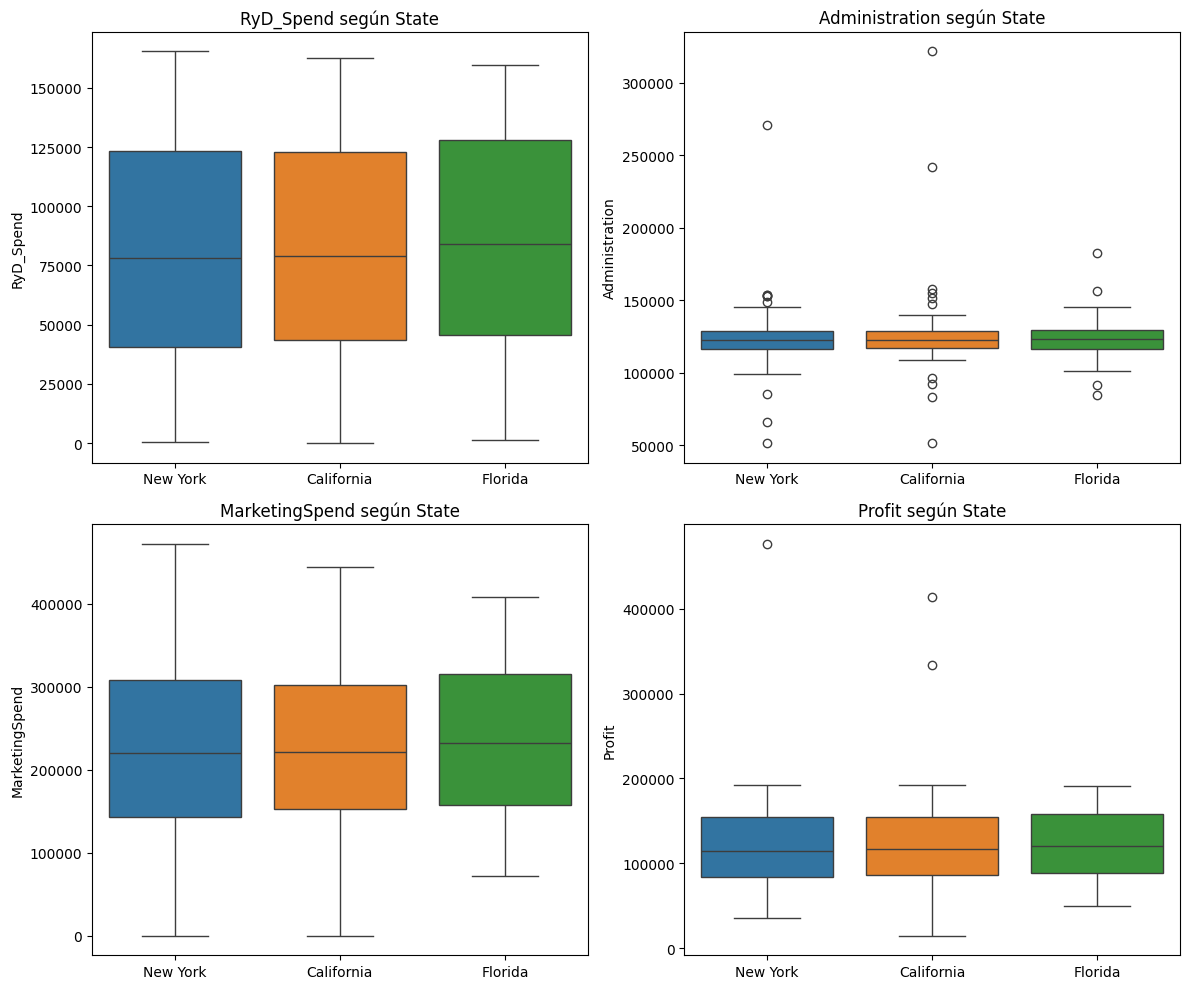

In [6]:
plt.figure(figsize=(12, 10))

for i, col in enumerate(cols_num):
    plt.subplot(2, 2, i+1)
    sns.boxplot(data=empresas, x='State', y=col, hue='State')
    plt.title(f'{col} según State')
    plt.xlabel('')

plt.tight_layout()
plt.show()

Se analizó la distribución de cada variable numérica según State. En los cuatro casos, las medianas y los rangos intercuartiles de New York, California y Florida son muy similares, y los los valores atípicos no se concentran en un único estado. Esto indica que la ubicación de la empresa no se asocia con diferencias en los gastos ni en el Profit, por lo que se decidió no incluir State como variable predictora.

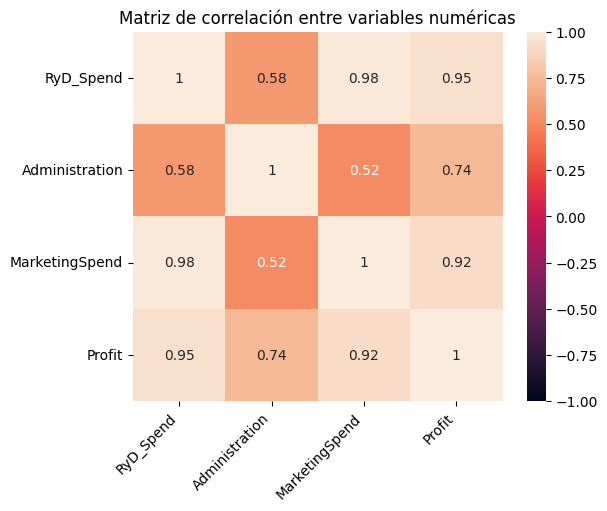

In [7]:
corr = empresas.drop(columns=["State"]).corr()

ax = sns.heatmap(corr,vmin=-1, vmax=1, square=True, annot=True)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, horizontalalignment='right')
plt.title('Matriz de correlación entre variables numéricas')
plt.show()

Profit presenta una correlación muy alta con RyD_Spend (0.95) y MarketingSpend (0.92), y moderada con Administration (0.74), por lo que se espera que RyD_Spend sea la variable más relevante en los cortes del árbol. Además, RyD_Spend y MarketingSpend están muy correlacionadas entre sí (0.98), lo que indica multicolinealidad para un modelo lineal, pero no para un árbol de decisión.

#### **División Conjuntos Train y Test:**

Se realizan la divisiones de los conjuntos de Train y Test. Uno con la proporción 80/20 y otro con la proporción 70/30.

In [8]:
X = empresas[['RyD_Spend', 'Administration', 'MarketingSpend']]
y = empresas['Profit']
X_train_80, X_test_20, y_train_80, y_test_20 = train_test_split(X, y, test_size=0.2, random_state=63)

print(f"Datos de entrenamiento: {X_train_80.shape} y de test: {X_test_20.shape}")

Datos de entrenamiento: (800, 3) y de test: (200, 3)


In [9]:
X_train_70, X_test_30, y_train_70, y_test_30 = train_test_split(X, y, test_size=0.3, random_state=63)

print(f"Datos de entrenamiento: {X_train_70.shape} y de test: {X_test_30.shape}")

Datos de entrenamiento: (700, 3) y de test: (300, 3)


#### Observación y tratamiento de outliers

No se estandarizaron las variables predictoras, ya que los árboles de decisión dividen cada variable por umbrales y no se ven afectados por la escala. Sin embargo, en el análisis exploratorio se observaron valores atípicos en la variable objetivo Profit. Dado que el árbol de regresión predice el promedio de cada hoja, estos valores pueden distorsionar sus predicciones. Por ello, se identifican mediante el criterio Q3 + 1,5·IQR, calculado sobre cada conjunto de entrenamiento.

In [10]:
Q1, Q3 = y_train_80.quantile([0.25, 0.75])
IQR = Q3 - Q1
lim_sup_80_20 = Q3 + 1.5 * IQR
print(f'Límite superior, div. 80-20: {lim_sup_80_20:.2f}')

X_train_80[y_train_80 > lim_sup_80_20].assign(Profit=y_train_80[y_train_80 > lim_sup_80_20])

Límite superior, div. 80-20: 257787.11


,RyD_Spend,Administration,MarketingSpend,Profit
998,128456.23,321652.14,281692.32,333962.19
997,100275.47,241926.31,227142.82,413956.48


In [11]:
Q1, Q3 = y_train_70.quantile([0.25, 0.75])
IQR = Q3 - Q1
lim_sup_70_30 = Q3 + 1.5 * IQR
print(f'Límite superior, div. 70-30: {lim_sup_70_30:.2f}')

X_train_70[y_train_70 > lim_sup_70_30].assign(Profit=y_train_70[y_train_70 > lim_sup_70_30])

Límite superior, div. 70-30: 259600.02


,RyD_Spend,Administration,MarketingSpend,Profit
998,128456.23,321652.14,281692.32,333962.19
997,100275.47,241926.31,227142.82,413956.48


En ambas particiones se identificaron las mismas dos empresas. Para evaluar si estos valores son coherentes con el resto de los datos, se compara su Profit con el Profit mediano de empresas con un nivel de inversión en RyD_Spend similar.

In [12]:
for idx in [997, 998]:
    ryd = X_train_80.loc[idx, 'RyD_Spend']
    similares = y_train_80[(X_train_80['RyD_Spend'] - ryd).abs() < 10000]
    print(f"Empresa {idx}: RyD = {ryd:.0f} | Profit = {y_train_80[idx]:.0f} | "
          f"Profit mediano de empresas similares = {similares.median():.0f}")

Empresa 997: RyD = 100275 | Profit = 413956 | Profit mediano de empresas similares = 136633
Empresa 998: RyD = 128456 | Profit = 333962 | Profit mediano de empresas similares = 159613


Empresa 997: Profit de 413.956, frente a un Profit mediano de 136.633 en empresas similares (aprox. 3 veces mayor).
Empresa 998: Profit de 333.962, frente a un Profit mediano de 159.613 en empresas similares (aprox. 2 veces mayor).

Estos valores no se explican por la inversión de las empresas y, además, ambas presentan valores extremos en Administration, lo que sugiere observaciones anómalas o errores de carga. Dada esta situación, se eliminan del conjunto de entrenamiento esas dos observaciones (menos del 0,3% del conjunto de entrenamiento). El conjunto de test no se modifica.

In [13]:
X_train_80 = X_train_80[y_train_80 <= lim_sup_80_20]
y_train_80 = y_train_80[y_train_80 <= lim_sup_80_20]

X_train_70 = X_train_70[y_train_70 <= lim_sup_70_30]
y_train_70 = y_train_70[y_train_70 <= lim_sup_70_30]

print(f"80/20 → train: {X_train_80.shape}, {y_train_80.shape}")
print(f"70/30 → train: {X_train_70.shape}, {y_train_70.shape}")

80/20 → train: (798, 3), (798,)
70/30 → train: (698, 3), (698,)


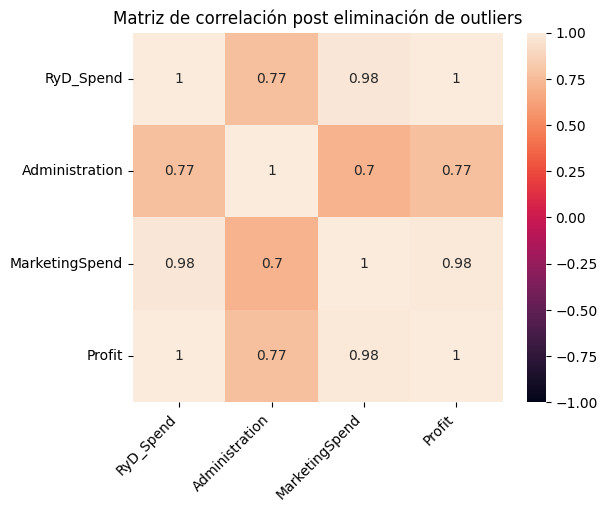

In [14]:
corr = X_train_80.assign(Profit=y_train_80).corr()
ax = sns.heatmap(corr,vmin=-1, vmax=1, square=True, annot=True)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, horizontalalignment='right')
plt.title('Matriz de correlación post eliminación de outliers')
plt.show()

Al comparar la matriz de correlación del dataset completo con la del conjunto de entrenamiento 80/20 sin los outliers removidos, se observa que todas las correlaciones aumentaron o se mantuvieron. Las relaciones de Profit con RyD_Spend (de 0.95 a prácticamente 1) y con MarketingSpend (de 0.92 a 0.98) se fortalecen, y los cambios más marcados se dan en Administration, cuya correlación con RyD_Spend y MarketingSpend sube cerca de 0.2 puntos. Esto confirma que las observaciones eliminadas no seguían el patrón general de los datos y debilitaban las relaciones entre variables.

### **Punto 2 - Árboles de decisión para regresión**

#### **Conjunto 80/20:**

a) Variando la profundidad del árbol (**max_deph**):

In [15]:
profundidades = [2, 6, 10, 14]

resultados = []

for prof in profundidades:

    tree_reg = DecisionTreeRegressor(max_depth=prof,criterion='squared_error',min_samples_leaf=1,min_samples_split=2,random_state=63)

    # Entrenamiento
    tree_reg.fit(X_train_80, y_train_80)

    # Predicciones
    y_pred = tree_reg.predict(X_test_20)

    # Métricas
    mae = round(mean_absolute_error(y_test_20, y_pred), 2)
    mse = round(mean_squared_error(y_test_20, y_pred), 2)
    rmse = round(np.sqrt(mse), 2)

    resultados.append({'max_depth': prof,'MAE': mae,'MSE': mse,'RMSE': rmse})

resultados_empresas1 = pd.DataFrame(resultados)
display(resultados_empresas1)

,max_depth,MAE,MSE,RMSE
0,2,10485.95,5.812224e+08,24108.55
1,6,2692.92,4.328169e+08,20804.25
2,10,2166.03,4.401294e+08,20979.26
3,14,2105.84,4.301543e+08,20740.16


Observaciones:

A profundidades bajas (max_depth=2) se evidencia subajuste (underfitting), con un MAE superior a 10.000. Al incrementar la profundidad hasta 14, el MAE disminuye de forma constante, alcanzando su mínimo (2.105,84). El RMSE, en cambio, se mantiene prácticamente estable entre 6 y 14, ya que está dominado por una única observación del conjunto de test (Profit ≈ 476.000) con un error muy grande; por eso la selección se basa en el MAE.

b) Variando el número mínimo de observaciones por hoja (**min_samples_leaf**) :

In [16]:
observaciones = [1, 3, 5]

resultados = []

for obs in observaciones:

    tree_reg = DecisionTreeRegressor(max_depth=14,criterion='squared_error',min_samples_leaf=obs,min_samples_split=2,random_state=63)

    # Entrenamiento
    tree_reg.fit(X_train_80, y_train_80)

    # Predicciones
    y_pred = tree_reg.predict(X_test_20)

    # Métricas
    mae = round(mean_absolute_error(y_test_20, y_pred), 2)
    mse = round(mean_squared_error(y_test_20, y_pred), 2)
    rmse = round(np.sqrt(mse), 2)

    resultados.append({'min_samples_leaf': obs,'MAE': mae,'MSE': mse,'RMSE': rmse})

resultados_empresas1 = pd.DataFrame(resultados)
display(resultados_empresas1)

,min_samples_leaf,MAE,MSE,RMSE
0,1,2105.84,4.301543e+08,20740.16
1,3,2337.60,4.420906e+08,21025.95
2,5,2428.37,4.331454e+08,20812.15


Observaciones:

Permitir hojas unitarias (min_samples_leaf=1) logra la mayor precisión puntual en las estimaciones. Restringir el tamaño mínimo de hoja a 3 o 5 incrementa el MAE y el RMSE, por lo que se conserva el valor 1 para capturar la alta correlación lineal que presenta la variable objetivo.

c) Variando el número mínimo de observaciones para realizar una separación (**min_samples_split**):

In [17]:
observaciones = [2, 5, 10, 15, 20]

resultados = []

for obs in observaciones:

    tree_reg = DecisionTreeRegressor(max_depth=14,criterion='squared_error',min_samples_leaf=1,min_samples_split=obs,random_state=63)

    # Entrenamiento
    tree_reg.fit(X_train_80, y_train_80)

    # Predicciones
    y_pred = tree_reg.predict(X_test_20)

    # Métricas
    mae = round(mean_absolute_error(y_test_20, y_pred), 2)
    mse = round(mean_squared_error(y_test_20, y_pred), 2)
    rmse = round(np.sqrt(mse), 2)

    resultados.append({'min_samples_split': obs,'MAE': mae,'MSE': mse,'RMSE': rmse})

resultados_empresas1 = pd.DataFrame(resultados)
display(resultados_empresas1)

,min_samples_split,MAE,MSE,RMSE
0,2,2105.84,4.301543e+08,20740.16
1,5,2217.57,4.312123e+08,20765.65
2,10,2392.22,4.602612e+08,21453.70
3,15,2641.15,4.601767e+08,21451.73
4,20,2610.65,4.334907e+08,20820.44


Observaciones:

El menor error se obtiene con min_samples_split=2. Valores mayores (como 10, 15 o 20) frenan prematuramente las particiones en rangos donde aún existía margen de ganancia en la reducción del error cuadrático

d) Visualización del árbol seleccionado:

In [18]:
tree_reg1 = DecisionTreeRegressor(max_depth=14, min_samples_leaf=1, min_samples_split=2,
                                  criterion='squared_error', random_state=63)
# Entrenamiento
tree_reg1.fit(X_train_80, y_train_80)

,"criterion criterion: {""squared_error"", ""friedman_mse"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in the half mean Poisson deviance to find splits... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",14
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",63
,"max_lea

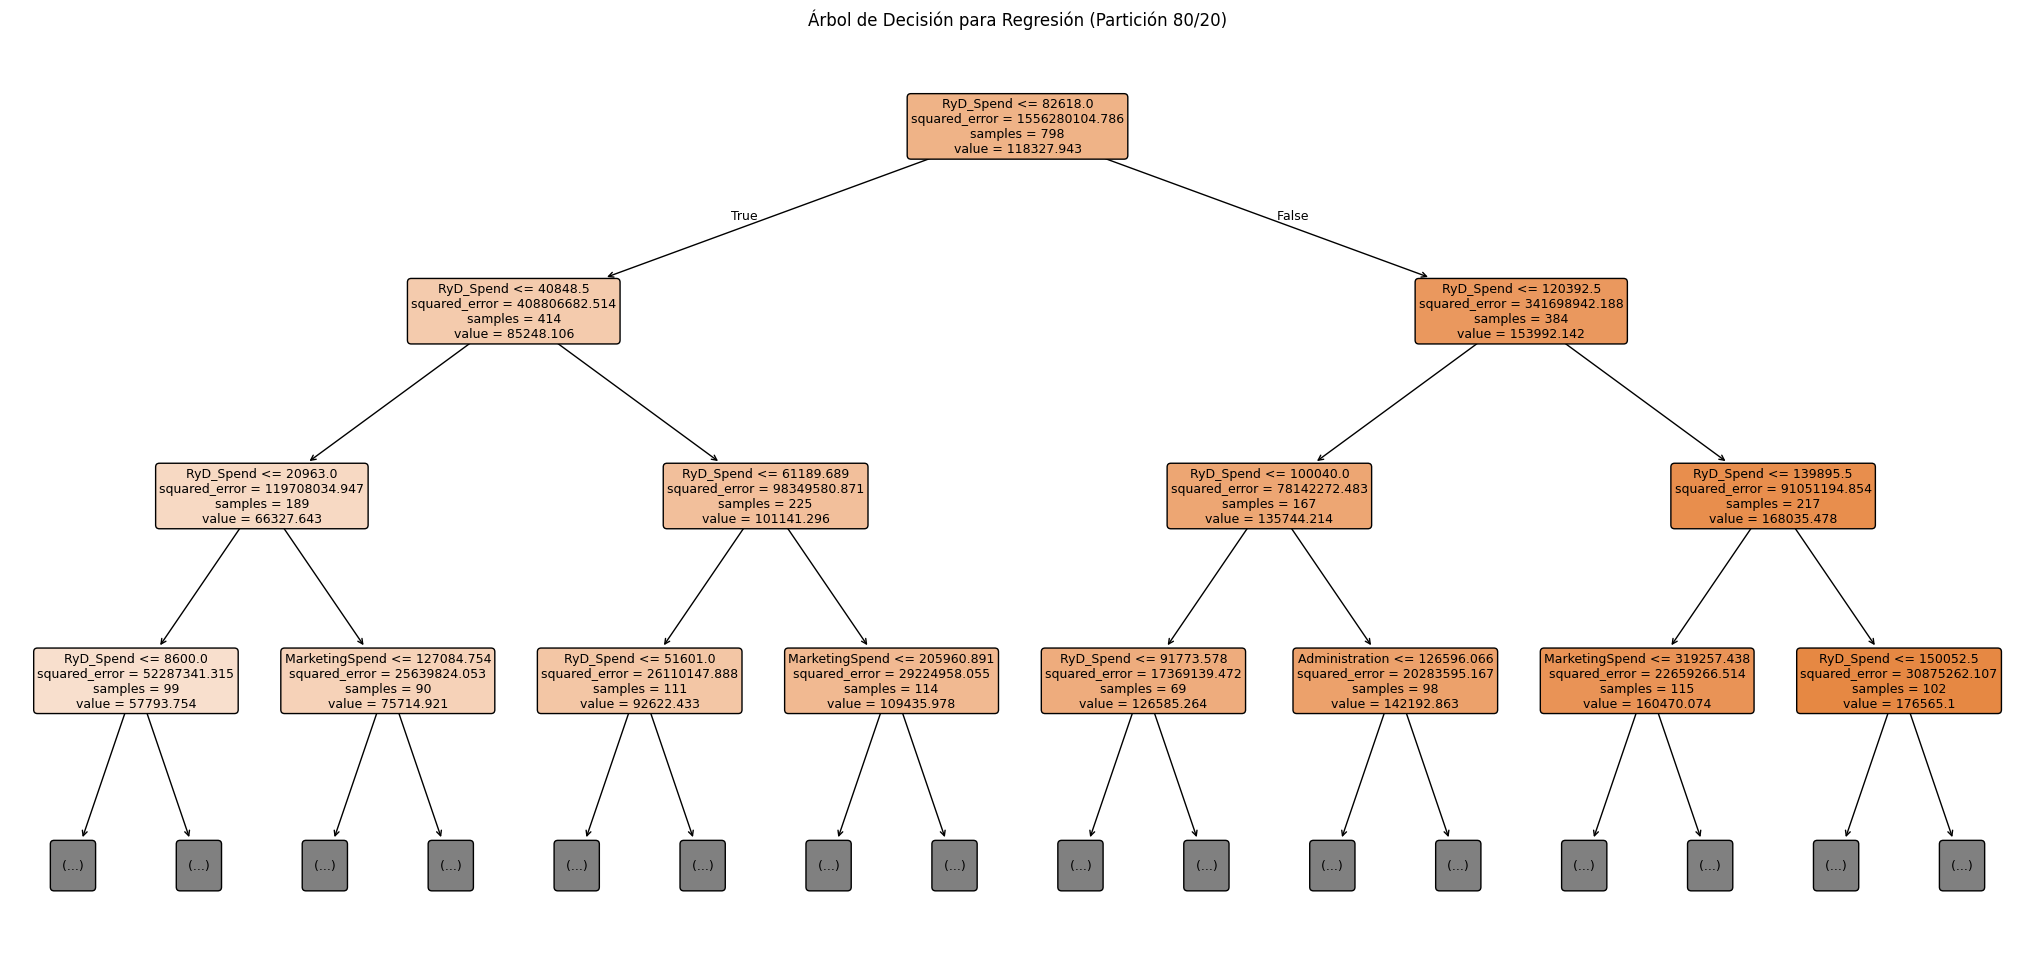

In [19]:
# Gráfico del árbol obtenido
plt.figure(figsize=(26, 12))
plot_tree(
    tree_reg1,
    feature_names=X_train_80.columns,
    filled=True,
    rounded=True,
    fontsize=9,
    max_depth=3  # Mostramos hasta el nivel 3 para que sea legible
)
plt.title("Árbol de Decisión para Regresión (Partición 80/20)")
plt.show()

Se grafican los primeros tres niveles del árbol seleccionado (max_depth = 14, min_samples_leaf = 1, min_samples_split = 2) para facilitar su lectura. Las primeras divisiones se realizan sobre RyD_Spend, lo que confirma que es la variable más relevante, en línea con su correlación casi perfecta con Profit. Las predicciones de las hojas aumentan progresivamente con RyD_Spend, lo que muestra cómo el árbol aproxima esa relación lineal mediante escalones. MarketingSpend y Administration recién aparecen en el cuarto nivel, como ajustes finos dentro de grupos ya separados por RyD_Spend.

#### **Conjunto 70/30:**

In [20]:
# Asignamos directamente las variables de la partición 70/30 ya definidas y procesadas anteriormente
X2_train = X_train_70
y2_train = y_train_70

X2_test = X_test_30
y2_test = y_test_30

a) Variando la profundidad del árbol ('max_deph'):

In [21]:

profundidades = [2, 4, 6, 8, 10, 14]
resultados_depth_70 = []

for prof in profundidades:
    tree_reg = DecisionTreeRegressor(
        max_depth=prof,
        criterion='squared_error',
        min_samples_leaf=1,
        min_samples_split=2,
        random_state=63
    )
    tree_reg.fit(X_train_70, y_train_70)
    y_pred = tree_reg.predict(X_test_30)

    mae = round(mean_absolute_error(y_test_30, y_pred), 2)
    mse = round(mean_squared_error(y_test_30, y_pred), 2)
    rmse = round(np.sqrt(mse), 2)

    resultados_depth_70.append({'max_depth': prof, 'MAE': mae, 'MSE': mse, 'RMSE': rmse})

display(pd.DataFrame(resultados_depth_70))

,max_depth,MAE,MSE,RMSE
0,2,9684.89,4.166035e+08,20410.87
1,4,3648.37,3.003179e+08,17329.68
2,6,2113.37,2.897558e+08,17022.22
3,8,1740.18,2.890326e+08,17000.96
4,10,1599.92,3.022256e+08,17384.64
5,14,1569.89,2.948581e+08,17171.43


Se determinó que el valor óptimo es max_depth = 14, ya que presenta el menor MAE (1.569,89). El MAE disminuye de forma sostenida al aumentar la profundidad, con mejoras cada vez menores a partir de 8. Al igual que en el 80/20, el RMSE se mantiene estable porque está dominado por una única observación del test con un error muy grande, por lo que la selección se basa en el MAE.

b) Variando el mínimo de observaciones por hoja (min_samples_leaf) con el mejor max_depth

In [22]:
# b) Variando el mínimo de observaciones por hoja (min_samples_leaf) con el mejor max_depth
observaciones_leaf = [1, 2, 3, 5, 7, 10]
resultados_leaf_70 = []

for obs in observaciones_leaf:
    tree_reg = DecisionTreeRegressor(
        max_depth=14,
        criterion='squared_error',
        min_samples_leaf=obs,
        min_samples_split=2,
        random_state=63
    )
    # entrenamiento
    tree_reg.fit(X_train_70, y_train_70)
    # predicciones
    y_pred = tree_reg.predict(X_test_30)
    # metricas
    mae = round(mean_absolute_error(y_test_30, y_pred), 2)
    mse = round(mean_squared_error(y_test_30, y_pred), 2)
    rmse = round(np.sqrt(mse), 2)

    resultados_leaf_70.append({'min_samples_leaf': obs, 'MAE': mae, 'MSE': mse, 'RMSE': rmse})

display(pd.DataFrame(resultados_leaf_70))

,min_samples_leaf,MAE,MSE,RMSE
0,1,1569.89,2.948581e+08,17171.43
1,2,1625.23,3.046493e+08,17454.21
2,3,1771.04,3.081454e+08,17554.07
3,5,1857.65,2.897577e+08,17022.27
4,7,1974.16,2.900622e+08,17031.21
5,10,2168.41,3.087564e+08,17571.47


Fijando max_depth = 14, se selecciona min_samples_leaf = 1, ya que presenta el menor MAE. Al aumentar el tamaño mínimo de hoja, el MAE crece de forma sostenida, porque el árbol pierde capacidad para aproximar con precisión la relación entre RyD_Spend y Profit.

c) Variando el número mínimo de observaciones para realizar una separación (min_samples_split):

In [23]:
observaciones_split = [2, 5, 10, 15, 20]
resultados_split_70 = []

for obs in observaciones_split:
    tree_reg = DecisionTreeRegressor(
        max_depth=14,
        criterion='squared_error',
        min_samples_leaf=1,
        min_samples_split=obs,
        random_state=63
    )
    tree_reg.fit(X_train_70, y_train_70)
    y_pred = tree_reg.predict(X_test_30)

    mae = round(mean_absolute_error(y_test_30, y_pred), 2)
    mse = round(mean_squared_error(y_test_30, y_pred), 2)
    rmse = round(np.sqrt(mse), 2)

    resultados_split_70.append({'min_samples_split': obs, 'MAE': mae, 'MSE': mse, 'RMSE': rmse})

display(pd.DataFrame(resultados_split_70))

,min_samples_split,MAE,MSE,RMSE
0,2,1569.89,2.948581e+08,17171.43
1,5,1610.59,3.116261e+08,17652.93
2,10,1844.59,3.100605e+08,17608.54
3,15,1997.23,3.058171e+08,17487.63
4,20,2136.54,2.904715e+08,17043.22


Fijando max_depth = 14 y min_samples_leaf = 1, se selecciona min_samples_split = 2, ya que presenta el menor MAE (1.569,89). Valores mayores impiden dividir nodos con pocas observaciones, lo que vuelve más gruesa la aproximación y aumenta el error.

d) Visualización del árbol seleccionado

In [24]:
# d) Entrenamiento del modelo final 70/30
tree_reg2 = DecisionTreeRegressor(
    max_depth=14,
    min_samples_leaf=1,
    min_samples_split=2,
    criterion='squared_error',
    random_state=63
)
tree_reg2.fit(X_train_70, y_train_70)


,"criterion criterion: {""squared_error"", ""friedman_mse"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in the half mean Poisson deviance to find splits... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",14
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",63
,"max_lea

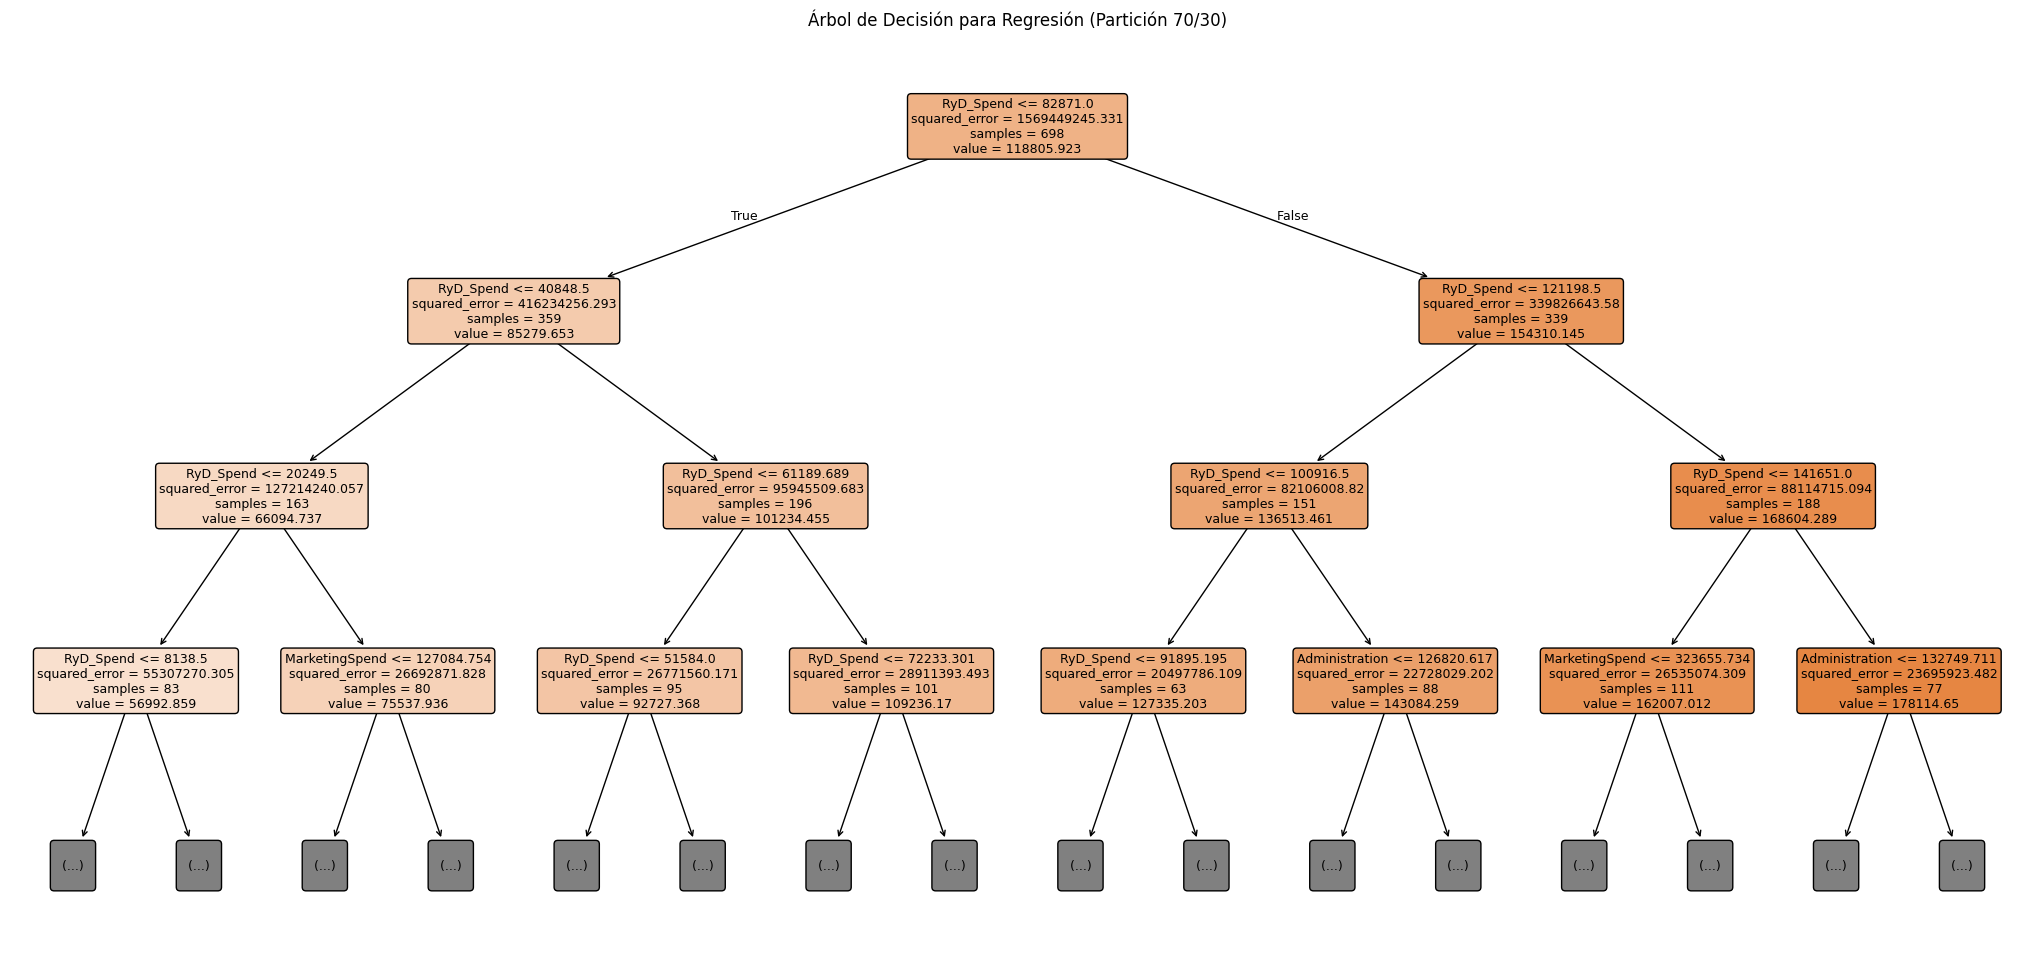

In [25]:
# Gráfico del árbol obtenido
plt.figure(figsize=(26, 12))
plot_tree(
    tree_reg2,
    feature_names=X_train_70.columns,
    filled=True,
    rounded=True,
    fontsize=9,
    max_depth=3  # Mostramos hasta el nivel 3 para que sea legible
)
plt.title("Árbol de Decisión para Regresión (Partición 70/30)")
plt.show()

Se grafican los primeros tres niveles del árbol seleccionado (max_depth = 14, min_samples_leaf = 1, min_samples_split = 2). Su estructura es prácticamente idéntica a la del árbol 80/20: los tres primeros niveles dividen exclusivamente por RyD_Spend, con umbrales casi iguales (por ejemplo, 82.871 frente a 82.618 en la raíz), y MarketingSpend y Administration aparecen recién en el cuarto nivel. Esto indica que el modelo aprende la misma relación independientemente de la partición, lo que refuerza su estabilidad.

### **Conclusiones:**

In [26]:
# Tabla comparativa de métricas sobre ambos conjuntos de test
resultados_finales = []

# 1. Evaluación Modelo Óptimo 80/20 sobre test_20
pred_80 = tree_reg1.predict(X_test_20)
mae_80 = mean_absolute_error(y_test_20, pred_80)
mse_80 = mean_squared_error(y_test_20, pred_80)
rmse_80 = np.sqrt(mse_80)

resultados_finales.append({
    'Modelo': '80/20 (depth=14, leaf=1, split=2)',
    'MAE': round(mae_80, 2),
    'MSE': round(mse_80, 2),
    'RMSE': round(rmse_80, 2)
})

# 2. Evaluación Modelo Óptimo 70/30 sobre test_30
pred_70 = tree_reg2.predict(X_test_30)
mae_70 = mean_absolute_error(y_test_30, pred_70)
mse_70 = mean_squared_error(y_test_30, pred_70)
rmse_70 = np.sqrt(mse_70)

resultados_finales.append({
    'Modelo': '70/30 (depth=14, leaf=1, split=2)',
    'MAE': round(mae_70, 2),
    'MSE': round(mse_70, 2),
    'RMSE': round(rmse_70, 2)
})

tabla_comparacion = pd.DataFrame(resultados_finales)
display(tabla_comparacion)

,Modelo,MAE,MSE,RMSE
0,"80/20 (depth=14, leaf=1, split=2)",2105.84,4.301543e+08,20740.16
1,"70/30 (depth=14, leaf=1, split=2)",1569.89,2.948581e+08,17171.43


Ambos modelos alcanzan un error bajo en relación con la escala de la variable objetivo: un MAE de 2.105,84 en el 80/20 y de 1.569,89 en el 70/30, lo que representa menos del 2% del Profit medio (≈119.500). La diferencia entre ambos se explica principalmente por la composición de cada conjunto de test, ya que los dos árboles aprendieron una estructura prácticamente idéntica.

El RMSE resulta muy superior al MAE en ambos casos (≈20.700 y ≈17.200) porque está dominado por una única observación presente en los dos conjuntos de test (Profit ≈ 476.000), cuyo error de aproximadamente 286.000 concentra casi todo el MSE. Por eso, el MAE es la métrica más representativa del desempeño del modelo sobre la mayoría de las observaciones.

En ambos árboles las primeras divisiones se realizan sobre RyD_Spend, en línea con su correlación casi perfecta con Profit (0,95 en el dataset completo y prácticamente 1 tras eliminar las observaciones anómalas).

---

## PARTE B - Clasificación (dataset drugType.csv)

### Funciones auxiliares

In [27]:

def target_balance(df, target_col):
    """Muestra la tabla de frecuencias absoluta y relativa de las clases."""
    cantidad = df[target_col].value_counts()
    porcentaje = df[target_col].value_counts(normalize=True) * 100
    tabla = pd.DataFrame({
        'Cantidad': cantidad,
        'Porcentaje': porcentaje.map('{:.1f}%'.format)
    })
    print(f"Distribución de clases para '{target_col}':")
    display(tabla)

def outliers_iqr(datos, var: str):
    """Detecta y remueve outliers según el rango intercuartil (IQR)."""
    Q1 = datos[var].quantile(0.25)
    Q3 = datos[var].quantile(0.75)
    IQR = Q3 - Q1
    lim_inf = Q1 - 1.5 * IQR
    lim_sup = Q3 + 1.5 * IQR

    cant_inic = len(datos)
    datos_limpios = datos[(datos[var] >= lim_inf) & (datos[var] <= lim_sup)]
    print(f"En '{var}': se eliminaron {cant_inic - len(datos_limpios)} filas (Límites: [{lim_inf:.2f}, {lim_sup:.2f}]).")
    return datos_limpios


def discretizar(datos_train, datos_test, columnas, n_bins):
    """
    Discretiza por frecuencia igual (cuantiles) usando los límites del Train para el Test.
    """
    datos_train = datos_train.copy()
    datos_test = datos_test.copy()

    for col in columnas:
        # 1. Calculamos los límites de los cuantiles únicamente sobre el TRAIN
        _, bins = pd.qcut(
            datos_train[col],
            q=n_bins,
            retbins=True,
            labels=False,
            duplicates='drop'
        )
        # 2. Extendemos los extremos a infinito para evitar NaN si en TEST hay valores fuera del rango
        bins[0] = -np.inf
        bins[-1] = np.inf
        # 3. Aplicamos los mismos cortes en TRAIN
        datos_train[f'{col}_disc'] = pd.cut(
            datos_train[col],
            bins=bins,
            labels=False,
            include_lowest=True
        )
        # 4. Aplicamos esos mismos límites sobre el TEST (evita data leakage)
        datos_test[f'{col}_disc'] = pd.cut(
            datos_test[col],
            bins=bins,
            labels=False,
            include_lowest=True
        )

    return datos_train, datos_test

### **Punto 3 - Preparación de datos y Análisis Exploratorio (EDA)**

In [28]:
# CARGA Y REVISIÓN INICIAL
farmac = pd.read_csv('drugType.csv')
farmac.info()


<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Edad        200 non-null    int64  
 1   Sexo        200 non-null    str    
 2   BP          200 non-null    str    
 3   Colesterol  200 non-null    str    
 4   Na_a_K      200 non-null    float64
 5   Droga       200 non-null    str    
dtypes: float64(1), int64(1), str(4)
memory usage: 12.7 KB


Se puede observar que el conjunto de datos no presenta datos faltantes.

In [29]:
farmac.head()


,Edad,Sexo,BP,Colesterol,Na_a_K,Droga
0,23,F,Alto,Alto,25.355,DrogaY
1,47,M,Bajo,Alto,13.093,DrogaC
2,47,M,Bajo,Alto,10.114,DrogaC
3,28,F,Normal,Alto,7.798,DrogaX
4,61,F,Bajo,Alto,18.043,DrogaY


In [30]:
# Verificamos el desbalance de clases de la variable objetivo
target_balance(farmac, 'Droga')

Distribución de clases para 'Droga':


,Cantidad,Porcentaje
Droga,,
DrogaY,91,45.5%
DrogaX,54,27.0%
DrogaA,23,11.5%
DrogaC,16,8.0%
DrogaB,16,8.0%


In [31]:
farmac.describe()

,Edad,Na_a_K
count,200.000000,200.000000
mean,44.315000,16.084485
std,16.544315,7.223956
min,15.000000,6.269000
25%,31.000000,10.445500
50%,45.000000,13.936500
75%,58.000000,19.380000
max,74.000000,38.247000


Análisis de Variables:

***Edad :***

**Media:** 44.31 | **Mediana:** 45  
Presenta una Media y una Mediana muy similar, lo que se puede asociar a una distribución aparentemente simetrica sin presencia de valores extremos.

**Rango:** 15 – 74  

**Desviación estándar:** 16.54


---
***Na_a_K:***

**Media:** 16.08 | **Mediana:** 13.93  
La media es mayor que la mediana, lo que indica una distribución asimétrica a la derecha: la mayoría de los pacientes presenta valores moderados y unos pocos tienen valores muy altos.

**Rango:** 6.26 – 38.24

**Desviación estándar:**  7.22

In [32]:
# Lista columnas categóricas
col_cat = ['Sexo','BP','Colesterol','Droga']

for col in col_cat:
    print(f"Valores únicos en {col}: {farmac[col].unique()}")

Valores únicos en Sexo: <ArrowStringArray>
['F', 'M']
Length: 2, dtype: str
Valores únicos en BP: <ArrowStringArray>
['Alto', 'Bajo', 'Normal']
Length: 3, dtype: str
Valores únicos en Colesterol: <ArrowStringArray>
['Alto', 'Normal']
Length: 2, dtype: str
Valores únicos en Droga: <ArrowStringArray>
['DrogaY', 'DrogaC', 'DrogaX', 'DrogaA', 'DrogaB']
Length: 5, dtype: str


***Sexo :***

**Valores:** F -M

---
***BP:***

**Valores:** Bajo - Normal - Alto

---
***Colesterol:***

**Valores:** Normal - Alto  

---
***Drogra:***

**Valores:** DrogaA - DrogaB - DrogaC- DrogaX - DrogaY



In [33]:
# CODIFICACIÓN DE CATEGÓRICAS

# Mapeo con orden lógico / ordinal para variables clínicas y binarias
farmac['Sexo_cod'] = farmac['Sexo'].map({'F': 1, 'M': 0})
farmac['BP_cod'] = farmac['BP'].map({'Bajo': 0, 'Normal': 1, 'Alto': 2})
farmac['Colesterol_cod'] = farmac['Colesterol'].map({'Normal': 0, 'Alto': 1})

# Codificación de la variable objetivo (Droga) de 0 a 4
map_droga = {'DrogaA': 0, 'DrogaB': 1, 'DrogaC': 2, 'DrogaX': 3, 'DrogaY': 4}
farmac['Droga_cod'] = farmac['Droga'].map(map_droga)

display(farmac[['Sexo', 'Sexo_cod', 'BP', 'BP_cod', 'Colesterol', 'Colesterol_cod', 'Droga', 'Droga_cod']].head())

,Sexo,Sexo_cod,BP,BP_cod,Colesterol,Colesterol_cod,Droga,Droga_cod
0,F,1,Alto,2,Alto,1,DrogaY,4
1,M,0,Bajo,0,Alto,1,DrogaC,2
2,M,0,Bajo,0,Alto,1,DrogaC,2
3,F,1,Normal,1,Alto,1,DrogaX,3
4,F,1,Bajo,0,Alto,1,DrogaY,4


#### División Conjuntos Train y Test:

 Realizamos la división de los conjuntos de Train y Test. Uno con la proporción 80/20 y otro con la proporción 70/30.

In [34]:
# Partición 80/20 con estratificación obligatoria
farmac1_train, farmac1_test = train_test_split(
    farmac,
    test_size=0.2,
    random_state=63,
    stratify=farmac['Droga_cod']
)
farmac1_train = farmac1_train.copy(deep=True)
farmac1_test = farmac1_test.copy(deep=True)


In [35]:

# Partición 70/30 con estratificación obligatoria
farmac2_train, farmac2_test = train_test_split(
    farmac,
    test_size=0.3,
    random_state=63,
    stratify=farmac['Droga_cod']
)
farmac2_train = farmac2_train.copy(deep=True)
farmac2_test = farmac2_test.copy(deep=True)

In [36]:
print(f"Partición 80/20 -> Train: {farmac1_train.shape}, Test: {farmac1_test.shape}")
print(f"Partición 70/30 -> Train: {farmac2_train.shape}, Test: {farmac2_test.shape}")

Partición 80/20 -> Train: (160, 10), Test: (40, 10)
Partición 70/30 -> Train: (140, 10), Test: (60, 10)


Analisis y tratamiento de los datos utilizados para train :

Conjunto 80/20

Se visualizan los boxplots de Edad y Na_a_K para identificar valores atípicos en el conjunto de entrenamiento.

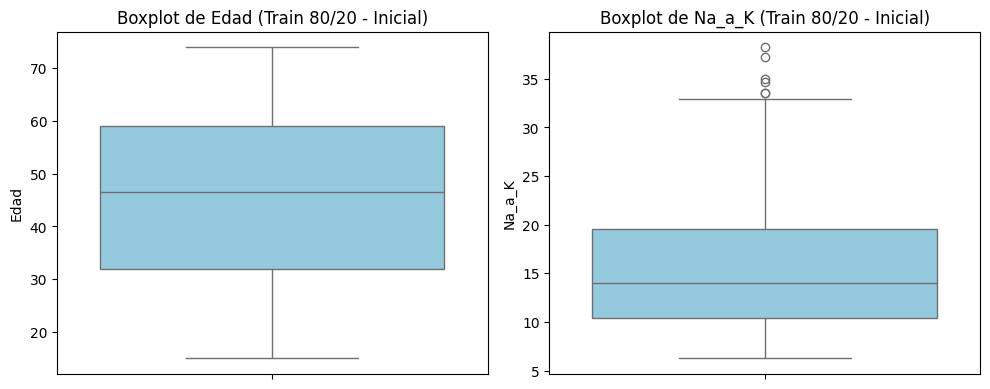

En 'Na_a_K': se eliminaron 6 filas (Límites: [-3.27, 33.26]).


In [37]:
# Visualización de outliers antes del filtrado
cols_num = ['Edad', 'Na_a_K']

plt.figure(figsize=(10, 4))
for i, col in enumerate(cols_num):
    plt.subplot(1, 2, i + 1)
    sns.boxplot(y=farmac1_train[col], color='skyblue')
    plt.title(f"Boxplot de {col} (Train 80/20 - Inicial)")
plt.tight_layout()
plt.show()

# Eliminación de outliers exclusivamente sobre farmac1_train
farmac1_train = outliers_iqr(farmac1_train, 'Na_a_K')

Se eliminaron los valores de Na_a_K superiores a Q3 + 1,5·IQR del conjunto de entrenamiento (6 observaciones en el 80/20 y 2 en el 70/30). No se trata de errores de carga: corresponden a pacientes de DrogaY, la clase mayoritaria, con relaciones sodio/potasio muy altas. Se eliminan para reducir su influencia en los modelos sensibles a valores extremos (la estimación de varianzas en GaussianNB y las distancias en k-NN). Como pertenecen a la clase con más observaciones, su eliminación no compromete la representación de ninguna droga. El conjunto de test no se modifica.

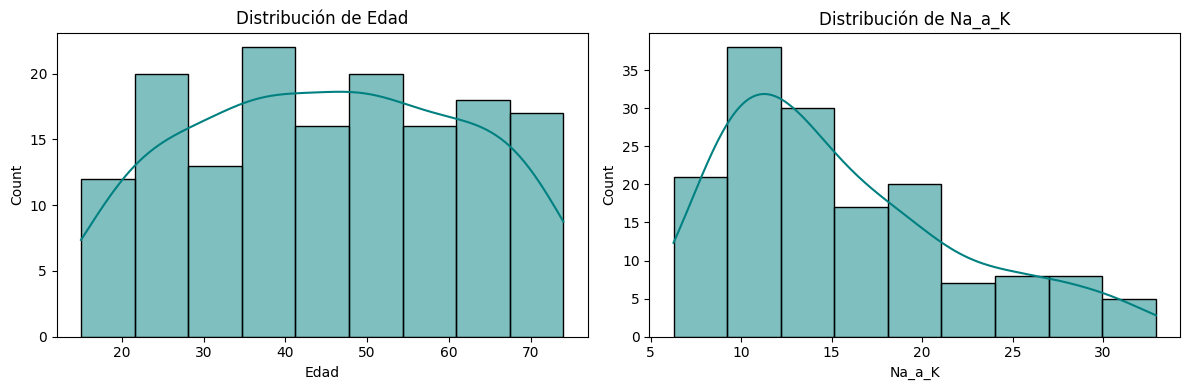

In [38]:
# Histogramas de variables numéricas
plt.figure(figsize=(12, 4))
for i, col in enumerate(cols_num):
    plt.subplot(1, 2, i + 1)
    sns.histplot(farmac1_train[col], kde=True, color='teal')
    plt.title(f"Distribución de {col}")
plt.tight_layout()
plt.show()


La Edad presenta una distribución aproximadamente uniforme entre 15 y 74 años, sin valores extremos. Na_a_K, en cambio, es asimétrica a la derecha: la mayoría de los pacientes se concentra entre 8 y 15, y la cola derecha corresponde a valores altos, que, como se verá más adelante, están asociados a DrogaY.

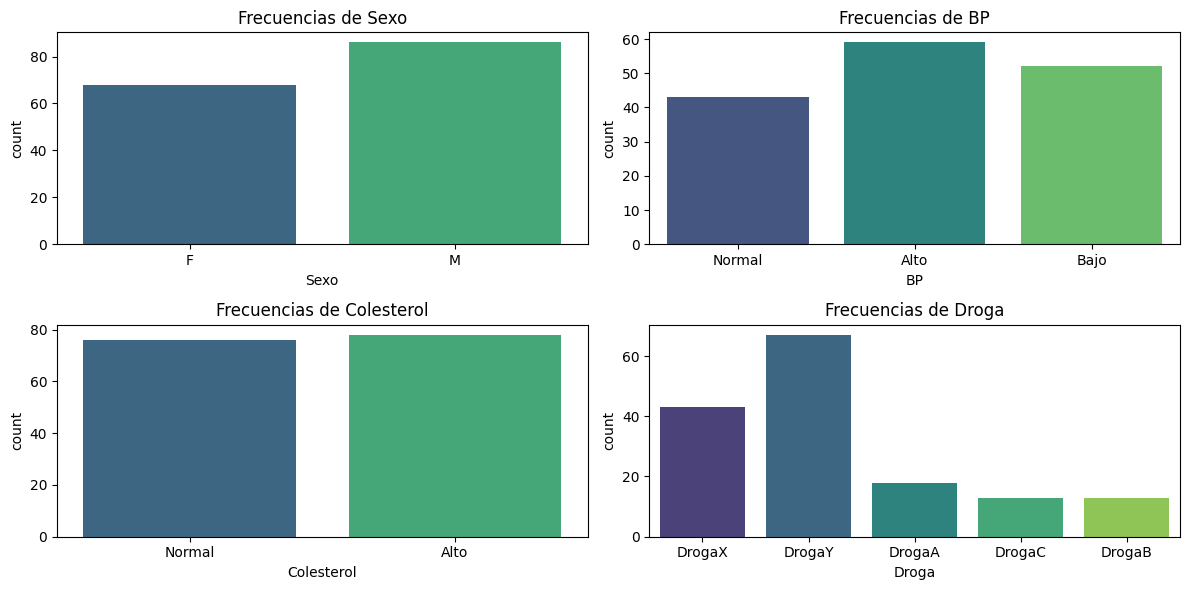

In [39]:
# Frecuencia de variables categóricas
col_cat = ['Sexo', 'BP', 'Colesterol', 'Droga']
plt.figure(figsize=(12, 6))
for i, col in enumerate(col_cat):
    plt.subplot(2, 2, i + 1)
    sns.countplot(data=farmac1_train, x=col, palette='viridis', hue=col, legend=False)
    plt.title(f"Frecuencias de {col}")
plt.tight_layout()
plt.show();

Observamos que la variable Droga presenta un marcado desbalance de clases. La DrogaY es la categoría con notablemente mas observaciones, mientras que A, B y C cuentan con muchas menos.

La variable Colesterol muestra una distribución uniforme, mientras que en Sexo y BP se observan ligeras predominancias de las categorías 'Masculino' y 'Alto'.

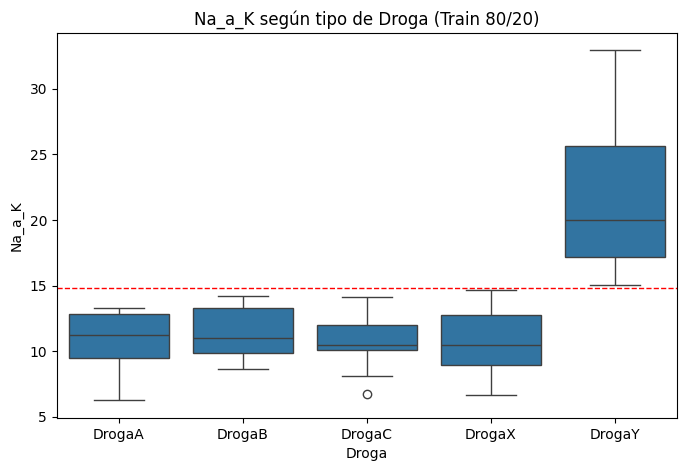

In [40]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=farmac1_train, x='Droga', y='Na_a_K',
            order=['DrogaA', 'DrogaB', 'DrogaC', 'DrogaX', 'DrogaY'])
plt.axhline(14.8, color='red', linestyle='--', linewidth=1)
plt.title("Na_a_K según tipo de Droga (Train 80/20)")
plt.show()

Na_a_K es la variable que mejor separa las clases: todos los pacientes de DrogaY presentan valores superiores a 15, mientras que las demás drogas se concentran por debajo de ese umbral, con distribuciones muy similares entre sí. Esto anticipa que será el primer corte del árbol de decisión. Las demás drogas no se distinguen por Na_a_K, por lo que su separación dependerá de otras variables, como la presión arterial y la edad.

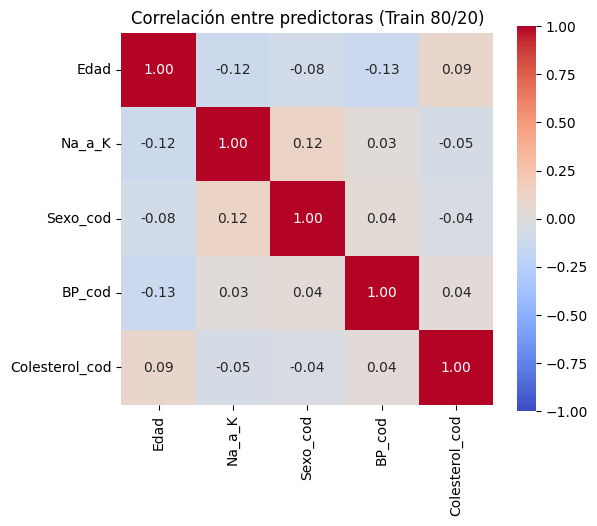

Droga,DrogaA,DrogaB,DrogaC,DrogaX,DrogaY
BP,,,,,
Alto,0.31,0.22,0.00,0.00,0.47
Bajo,0.00,0.00,0.25,0.29,0.46
Normal,0.00,0.00,0.00,0.65,0.35


Droga,DrogaA,DrogaB,DrogaC,DrogaX,DrogaY
Colesterol,,,,,
Alto,0.13,0.09,0.17,0.19,0.42
Normal,0.11,0.08,0.00,0.37,0.45


Droga,DrogaA,DrogaB,DrogaC,DrogaX,DrogaY
Sexo,,,,,
F,0.10,0.06,0.09,0.29,0.46
M,0.13,0.10,0.08,0.27,0.42


In [41]:
# Correlaciones entre predictoras numéricas/codificadas
plt.figure(figsize=(6, 5))
sns.heatmap(farmac1_train[['Edad', 'Na_a_K', 'Sexo_cod', 'BP_cod', 'Colesterol_cod']].corr(),
            vmin=-1, vmax=1, annot=True, fmt='.2f', cmap='coolwarm', square=True)
plt.title('Correlación entre predictoras (Train 80/20)')
plt.show()

# Relación de las categóricas con la variable objetivo
for col in ['BP', 'Colesterol', 'Sexo']:
    display(pd.crosstab(farmac1_train[col], farmac1_train['Droga'], normalize='index').round(2))

Las correlaciones entre las variables predictoras son muy bajas, por lo que pueden considerarse prácticamente independientes entre sí, ya que no hay información redundante entre predictoras.

Las tablas de contingencia muestran cómo se relaciona cada variable categórica con la droga:

- **Presión arterial:** es la variable categórica más informativa. Con presión alta solo aparecen DrogaA, DrogaB y DrogaY; con presión baja, DrogaC, DrogaX y DrogaY; con presión normal, únicamente DrogaX y DrogaY.
- **Colesterol:** DrogaC aparece solo en pacientes con colesterol alto (0% con colesterol normal), por lo que esta variable permitiría distinguir DrogaC de DrogaX.
- **Sexo:** las proporciones de cada droga son prácticamente iguales en hombres y mujeres, por lo que no aporta información para la clasificación.

DrogaY mantiene una proporción similar (entre 35% y 47%) en todos los niveles de las tres variables, lo que confirma que no depende de ellas sino de Na_a_K. En conjunto, se espera que el árbol de decisión corte primero por Na_a_K, luego por presión arterial y que use la edad y el colesterol para terminar de separar las drogas restantes.

#### Conjunto 70/30

Se aplica el mismo tratamiento de outliers que en el 80/20.

In [42]:
# Eliminación de outliers exclusivamente sobre farmac2_train
farmac2_train = outliers_iqr(farmac2_train, 'Na_a_K')

En 'Na_a_K': se eliminaron 2 filas (Límites: [-5.18, 36.30]).



Las proporciones de las clases (Droga) y de las variables categóricas se mantienen prácticamente idénticas al 80/20 gracias a haber aplicado la estratificación en el split.

Separación final de matrices X e y para modelado

In [43]:
# Variables predictoras y objetivo
features = ['Edad', 'Sexo_cod', 'BP_cod', 'Colesterol_cod', 'Na_a_K']
target = 'Droga_cod'

# Partición 80/20
X1_train = farmac1_train[features]
y1_train = farmac1_train[target]
X1_test = farmac1_test[features]
y1_test = farmac1_test[target]

# Partición 70/30
X2_train = farmac2_train[features]
y2_train = farmac2_train[target]
X2_test = farmac2_test[features]
y2_test = farmac2_test[target]

print(f"80/20 -> X1_train: {X1_train.shape}, X1_test: {X1_test.shape}")
print(f"70/30 -> X2_train: {X2_train.shape}, X2_test: {X2_test.shape}")

80/20 -> X1_train: (154, 5), X1_test: (40, 5)
70/30 -> X2_train: (138, 5), X2_test: (60, 5)


### **Punto 4 - Árbol de dicisión para clasificación:**


#### a) Variando la profundidad del árbol ('max_deph'):

In [44]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, classification_report
from sklearn.model_selection import cross_val_score

In [45]:
profundidades = [2, 3, 4, 6, 8]
res_depth_80 = []

for prof in profundidades:
    tree_clf = DecisionTreeClassifier(
        max_depth=prof,
        criterion='gini',
        min_samples_leaf=1,
        min_samples_split=2,
        random_state=63
    )
    tree_clf.fit(X1_train, y1_train)
    y_pred = tree_clf.predict(X1_test)

    res_depth_80.append({
        'max_depth': prof,
        'Accuracy': round(accuracy_score(y1_test, y_pred), 3),
        'Precision_macro': round(precision_score(y1_test, y_pred, average='macro', zero_division=0), 3),
        'Recall_macro': round(recall_score(y1_test, y_pred, average='macro', zero_division=0), 3)
    })

display(pd.DataFrame(res_depth_80))

,max_depth,Accuracy,Precision_macro,Recall_macro
0,2,0.850,0.482,0.6
1,3,0.925,0.757,0.8
2,4,1.000,1.000,1.0
3,6,1.000,1.000,1.0
4,8,1.000,1.000,1.0


In [46]:
arbol = DecisionTreeClassifier(max_depth=4, random_state=63)
print("Accuracy train:", arbol.fit(X1_train, y1_train).score(X1_train, y1_train))

cv = cross_val_score(arbol, X1_train, y1_train, cv=5, scoring='accuracy')
print("Accuracy por fold:", cv.round(3))
print(f"Promedio: {cv.mean():.3f} ± {cv.std():.3f}")

Accuracy train: 1.0
Accuracy por fold: [0.968 1.    0.968 1.    1.   ]
Promedio: 0.987 ± 0.016


Con max_depth = 2 y 3 el árbol no logra separar todas las clases: las métricas macro bajan porque alguna droga minoritaria no se predice correctamente. A partir de max_depth = 4 el modelo clasifica correctamente todo el conjunto de test. Para descartar sobreajuste, se evaluó el árbol mediante validación cruzada de 5 folds sobre el conjunto de entrenamiento, obteniendo una accuracy promedio de 0,987 ± 0,016 (entre 0,968 y 1) y una accuracy en train de 1. El desempeño es alto y estable entre folds y coincide con el de test, por lo que el modelo generaliza correctamente. Se selecciona max_depth = 4, la menor profundidad que alcanza el máximo desempeño.

#### b) Variando el número mínimo de observaciones por hoja (min_samples_leaf) :

In [47]:
hojas = [1, 3, 5, 10]
resultados_leaf_80 = []

for h in hojas:
    tree_clf = DecisionTreeClassifier(
        max_depth=4,
        criterion='gini',
        min_samples_leaf=h,
        min_samples_split=2,
        random_state=63
    )
    tree_clf.fit(X1_train, y1_train)
    y_pred = tree_clf.predict(X1_test)

    accuracy = accuracy_score(y1_test, y_pred)
    precision = precision_score(y1_test, y_pred, average='macro', zero_division=0)
    recall = recall_score(y1_test, y_pred, average='macro')

    resultados_leaf_80.append({
        'min_samples_leaf': h,
        'Accuracy': round(accuracy, 3),
        'Precision_macro': round(precision, 3),
        'Recall_macro': round(recall, 3)
    })

display(pd.DataFrame(resultados_leaf_80))

,min_samples_leaf,Accuracy,Precision_macro,Recall_macro
0,1,1.0,1.0,1.0
1,3,1.0,1.0,1.0
2,5,1.0,1.0,1.0
3,10,1.0,1.0,1.0


Observamos que las métricas permanecen constantes para todos los valores evaluados. Esto indica que el árbol ya presenta una estructura estable con la profundidad seleccionada y que modificar la cantidad mínima de observaciones por hoja no genera cambios significativos en el rendimiento del modelo.

#### c) Variando el número mínimo de observaciones para realizar una separación (min_samples_split):

In [48]:
splits = [2, 3, 5, 10]
resultados_split_80 = []

for s in splits:
    tree_clf = DecisionTreeClassifier(
        max_depth=4,
        criterion='gini',
        min_samples_leaf=1,
        min_samples_split=s,
        random_state=63
    )
    tree_clf.fit(X1_train, y1_train)
    y_pred = tree_clf.predict(X1_test)

    accuracy = accuracy_score(y1_test, y_pred)
    precision = precision_score(y1_test, y_pred, average='macro', zero_division=0)
    recall = recall_score(y1_test, y_pred, average='macro')

    resultados_split_80.append({
        'min_samples_split': s,
        'Accuracy': round(accuracy, 3),
        'Precision_macro': round(precision, 3),
        'Recall_macro': round(recall, 3)
    })

display(pd.DataFrame(resultados_split_80))

,min_samples_split,Accuracy,Precision_macro,Recall_macro
0,2,1.0,1.0,1.0
1,3,1.0,1.0,1.0
2,5,1.0,1.0,1.0
3,10,1.0,1.0,1.0


Al analizar los hiperparámetros min_samples_leaf y min_samples_split, observamos que no se produjeron cambios en las métricas para los distintos valores evaluados. Esto indica que, una vez fijada la profundidad máxima del árbol, la estructura del modelo permanece estable frente a variaciones en estos parámetros. Por este motivo, seleccionamos los valores mínimos evaluados: min_samples_leaf = 1 y min_samples_split = 2.

#### d) Visualización árbol antes de la poda:

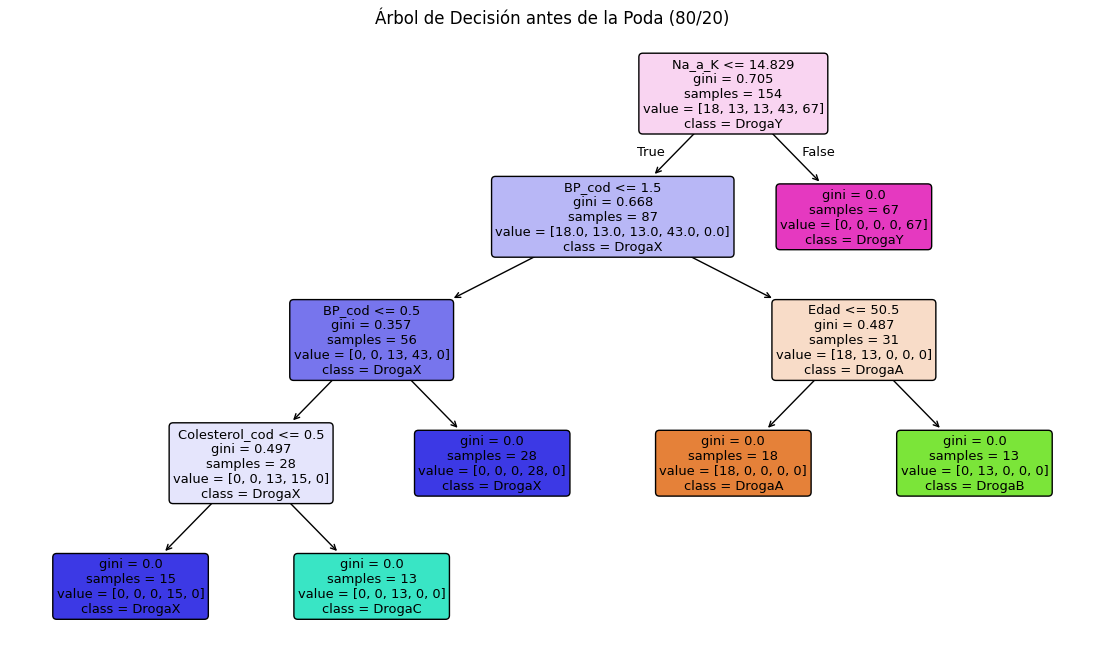

In [49]:
tree_sin_poda_80 = DecisionTreeClassifier(
    max_depth=4,
    min_samples_leaf=1,
    min_samples_split=2,
    criterion='gini',
    random_state=63
)
tree_sin_poda_80.fit(X1_train, y1_train)

nombres_clases = ['DrogaA', 'DrogaB', 'DrogaC', 'DrogaX', 'DrogaY']

plt.figure(figsize=(14, 8))
plot_tree(
    tree_sin_poda_80,
    feature_names=X1_train.columns,
    class_names=nombres_clases,
    filled=True,
    rounded=True
)
plt.title("Árbol de Decisión antes de la Poda (80/20)")
plt.show()

Observaciones:

- **Primer corte, Na_a_K ≤ 14,829:** separa de una sola vez los 67 pacientes de DrogaY. Coincide con el umbral observado en el boxplot de Na_a_K por droga (≈14,8).
- **Segundo nivel, presión arterial (BP_cod ≤ 1,5):** divide al resto entre presión alta (31 pacientes: DrogaA y DrogaB) y presión baja o normal (56: DrogaC y DrogaX).
- **Presión alta:** la edad (≤ 50,5 años) separa DrogaA (18) de DrogaB (13).
- **Presión baja o normal:** con presión normal todos los pacientes reciben DrogaX (28). Con presión baja, el colesterol distingue DrogaX (colesterol normal, 15) de DrogaC (colesterol alto, 13).

Esto confirma la hipótesis previa: Na_a_K define DrogaY, y las demás drogas se separan por presión arterial y edad. El colesterol, como se anticipó en las tablas de contingencia, solo interviene para aislar DrogaC dentro de los pacientes con presión baja.

#### e) Visualización árbol despues de la poda:

In [50]:
path = DecisionTreeClassifier(max_depth=4, random_state=63).cost_complexity_pruning_path(X1_train, y1_train)
res = []
for a in path.ccp_alphas:
    t = DecisionTreeClassifier(max_depth=4, ccp_alpha=a, random_state=63).fit(X1_train, y1_train)
    p = t.predict(X1_test)
    res.append({'ccp_alpha': round(a, 4), 'Hojas': t.get_n_leaves(),
                'Accuracy': accuracy_score(y1_test, p),
                'Precision_macro': precision_score(y1_test, p, average='macro', zero_division=0),
                'Recall_macro': recall_score(y1_test, p, average='macro', zero_division=0)})
display(pd.DataFrame(res).round(3))

,ccp_alpha,Hojas,Accuracy,Precision_macro,Recall_macro
0,0.000,6,1.000,1.000,1.0
1,0.065,4,0.925,0.757,0.8
2,0.098,3,0.850,0.482,0.6
3,0.150,2,0.725,0.300,0.4
4,0.327,1,0.450,0.090,0.2


Observaciones:

Para seleccionar ccp_alpha se recorrieron los valores efectivos del camino de poda (cost_complexity_pruning_path). Sin poda, el árbol tiene 6 hojas y clasifica correctamente todas las observaciones del test. El primer valor que poda el árbol (α = 0,065) lo reduce a 4 hojas y provoca una caída de la Precision macro (0,757) y del Recall macro (0,8): como el problema tiene 5 clases, un árbol con 4 hojas no puede asignar una hoja a cada droga, por lo que al menos una clase deja de predecirse. Valores mayores de α degradan aún más el desempeño. Dado que el árbol sin poda ya presenta una estructura mínima, se selecciona ccp_alpha = 0.

#### f) Árbol después de la poda (80/20)

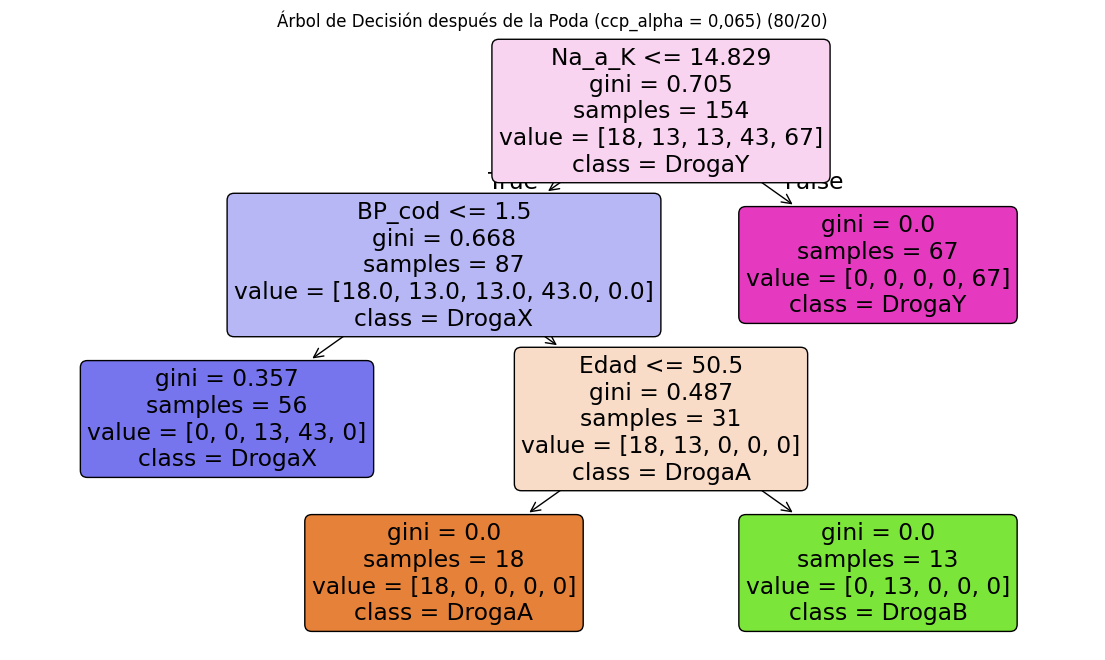

In [51]:
# efecto de la poda
tree_podado_80 = DecisionTreeClassifier(max_depth=4, ccp_alpha=0.065, random_state=63).fit(X1_train, y1_train)

plt.figure(figsize=(14, 8))
plot_tree(tree_podado_80, feature_names=X1_train.columns, class_names=nombres_clases,
          filled=True, rounded=True)
plt.title("Árbol de Decisión después de la Poda (ccp_alpha = 0,065) (80/20)")
plt.show()

# Modelo final: max_depth = 4, ccp_alpha = 0
tree_8020 = tree_sin_poda_80
y_pred_80 = tree_8020.predict(X1_test)
accuracy_8020  = accuracy_score(y1_test, y_pred_80)
precision_8020 = precision_score(y1_test, y_pred_80, average='macro', zero_division=0)
recall_8020    = recall_score(y1_test, y_pred_80, average='macro', zero_division=0)

El árbol podado con α = 0,065 conserva la estructura principal: el primer corte separa DrogaY (Na_a_K > 14,8), luego la presión arterial divide al resto, y entre los pacientes con presión alta la edad distingue DrogaA de DrogaB. Sin embargo, la poda elimina el corte que separaba DrogaC de DrogaX entre los pacientes con presión baja o normal: ambas quedan en una misma hoja (13 casos de DrogaC y 43 de DrogaX) que predice siempre DrogaX. Como resultado, DrogaC nunca se predice, lo que explica la caída del Recall macro a 0,8 (una de las cinco clases con recall 0). Esto confirma que el corte eliminado es necesario y justifica mantener el árbol sin podar (ccp_alpha = 0).

#### Conjunto 70/30:

#### a) Variando la profundidad del árbol ('max_deph'):

In [52]:
profundidades = [2, 3, 4, 6, 8]
resultados_depth_70 = []

for prof in profundidades:
    tree_clf = DecisionTreeClassifier(
        max_depth=prof,
        criterion='gini',
        min_samples_leaf=1,
        min_samples_split=2,
        random_state=63
    )
    tree_clf.fit(X2_train, y2_train)
    y_pred = tree_clf.predict(X2_test)

    resultados_depth_70.append({
        'max_depth': prof,
        'Accuracy': round(accuracy_score(y2_test, y_pred), 3),
        'Precision_macro': round(precision_score(y2_test, y_pred, average='macro', zero_division=0), 3),
        'Recall_macro': round(recall_score(y2_test, y_pred, average='macro'), 3)
    })

display(pd.DataFrame(resultados_depth_70))

,max_depth,Accuracy,Precision_macro,Recall_macro
0,2,0.833,0.469,0.6
1,3,0.917,0.752,0.8
2,4,1.000,1.000,1.0
3,6,1.000,1.000,1.0
4,8,1.000,1.000,1.0


Al igual que en la partición 80/20, con max_depth = 2 y 3 el árbol no logra separar todas las clases, mientras que a partir de max_depth = 4 clasifica correctamente todo el conjunto de test. Se selecciona max_depth = 4, la menor profundidad que alcanza el máximo desempeño, en línea con lo validado mediante validación cruzada en la partición 80/20.

#### b) Variando el número mínimo de observaciones por hoja (min_samples_leaf) :

In [53]:
hojas = [1, 3, 5, 10]
resultados_leaf_70 = []

for h in hojas:
    tree_clf = DecisionTreeClassifier(
        max_depth=4,
        criterion='gini',
        min_samples_leaf=h,
        min_samples_split=2,
        random_state=63
    )
    tree_clf.fit(X2_train, y2_train)
    y_pred = tree_clf.predict(X2_test)

    resultados_leaf_70.append({
        'min_samples_leaf': h,
        'Accuracy': round(accuracy_score(y2_test, y_pred), 3),
        'Precision_macro': round(precision_score(y2_test, y_pred, average='macro', zero_division=0), 3),
        'Recall_macro': round(recall_score(y2_test, y_pred, average='macro'), 3)
    })

display(pd.DataFrame(resultados_leaf_70))

,min_samples_leaf,Accuracy,Precision_macro,Recall_macro
0,1,1.0,1.0,1.0
1,3,1.0,1.0,1.0
2,5,1.0,1.0,1.0
3,10,1.0,1.0,1.0


#### c) Variando el número mínimo de observaciones para realizar una separación (min_samples_split):

In [54]:
# c) Variando el mínimo de observaciones para división (min_samples_split)
splits = [2, 3, 5, 10]
resultados_split_70 = []

for s in splits:
    tree_clf = DecisionTreeClassifier(
        max_depth=4,
        criterion='gini',
        min_samples_leaf=1,
        min_samples_split=s,
        random_state=63
    )
    tree_clf.fit(X2_train, y2_train)
    y_pred = tree_clf.predict(X2_test)

    resultados_split_70.append({
        'min_samples_split': s,
        'Accuracy': round(accuracy_score(y2_test, y_pred), 3),
        'Precision_macro': round(precision_score(y2_test, y_pred, average='macro', zero_division=0), 3),
        'Recall_macro': round(recall_score(y2_test, y_pred, average='macro'), 3)
    })

display(pd.DataFrame(resultados_split_70))

,min_samples_split,Accuracy,Precision_macro,Recall_macro
0,2,1.0,1.0,1.0
1,3,1.0,1.0,1.0
2,5,1.0,1.0,1.0
3,10,1.0,1.0,1.0


Una vez fijada max_depth = 4, ni min_samples_leaf ni min_samples_split modifican las métricas, ya que el árbol separa las clases con pocas divisiones y hojas puras. Se seleccionan los valores por defecto: min_samples_leaf = 1 y min_samples_split = 2.

#### d) Visualización árbol antes de la poda:

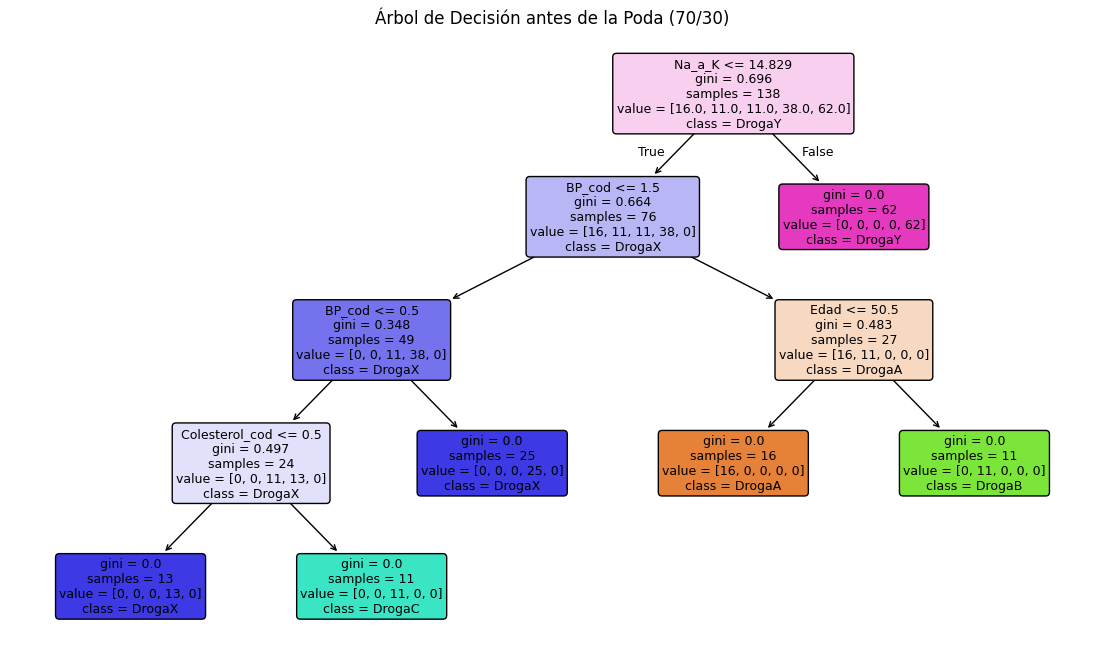

In [55]:
# d) Árbol seleccionado para 70/30 y su visualización
tree_7030 = DecisionTreeClassifier(
    max_depth=4,
    min_samples_leaf=1,
    min_samples_split=2,
    criterion='gini',
    random_state=63
)
tree_7030.fit(X2_train, y2_train)
y_pred_70 = tree_7030.predict(X2_test)

accuracy_7030 = accuracy_score(y2_test, y_pred_70)
precision_7030 = precision_score(y2_test, y_pred_70, average='macro', zero_division=0)
recall_7030 = recall_score(y2_test, y_pred_70, average='macro')

plt.figure(figsize=(14, 8))
nombres_clases = ['DrogaA', 'DrogaB', 'DrogaC', 'DrogaX', 'DrogaY']
plot_tree(
    tree_7030,
    feature_names=X2_train.columns,
    class_names=nombres_clases,
    filled=True,
    rounded=True
)
plt.title("Árbol de Decisión antes de la Poda (70/30)")
plt.show()

El árbol de la partición 70/30 tiene exactamente la misma estructura que el del 80/20: los mismos cortes en el mismo orden (Na_a_K ≤ 14,829, BP_cod, Edad ≤ 50,5 y Colesterol_cod), 6 hojas puras y los mismos umbrales. Solo cambia la cantidad de pacientes en cada nodo, por el distinto tamaño del conjunto de entrenamiento. Esto indica que las reglas aprendidas son estables y no dependen de la partición.

#### e) Visualización árbol despues de la poda:

In [56]:
path = DecisionTreeClassifier(max_depth=4, random_state=63).cost_complexity_pruning_path(X2_train, y2_train)
res = []
for a in path.ccp_alphas:
    t = DecisionTreeClassifier(max_depth=4, ccp_alpha=a, random_state=63).fit(X2_train, y2_train)
    p = t.predict(X2_test)
    res.append({'ccp_alpha': round(a, 4), 'Hojas': t.get_n_leaves(),
                'Accuracy': accuracy_score(y2_test, p),
                'Precision_macro': precision_score(y2_test, p, average='macro', zero_division=0),
                'Recall_macro': recall_score(y2_test, p, average='macro', zero_division=0)})
display(pd.DataFrame(res).round(3))

,ccp_alpha,Hojas,Accuracy,Precision_macro,Recall_macro
0,0.000,6,1.000,1.000,1.0
1,0.062,4,0.917,0.752,0.8
2,0.094,3,0.833,0.469,0.6
3,0.148,2,0.717,0.297,0.4
4,0.331,1,0.450,0.090,0.2


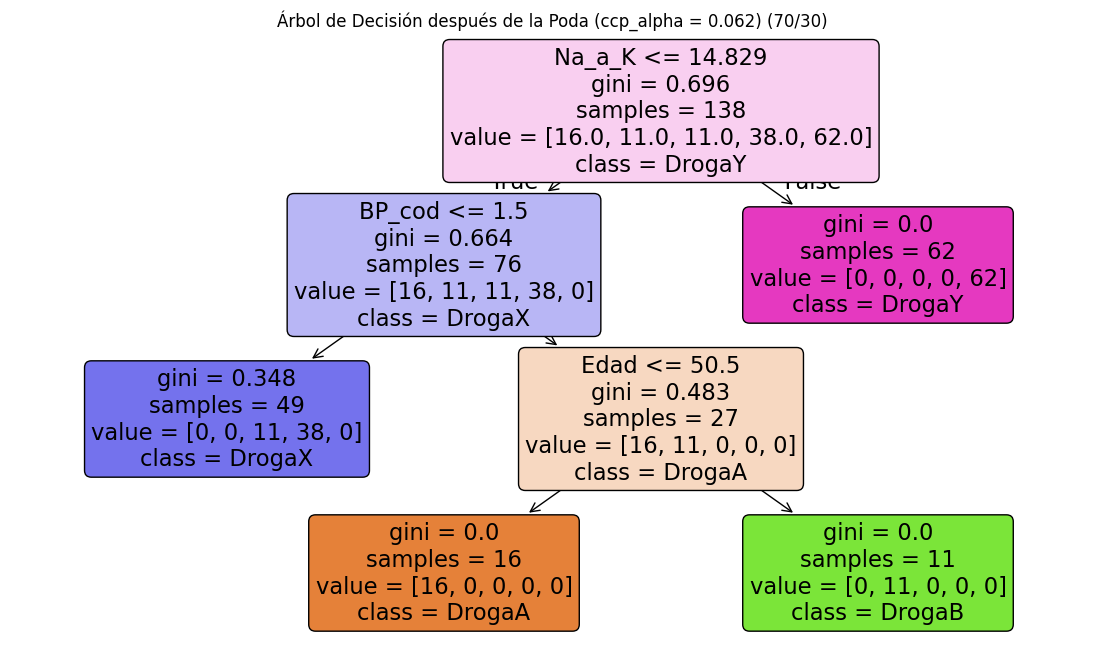

In [57]:
alpha_70 = path.ccp_alphas[1]
tree_podado_70 = DecisionTreeClassifier(max_depth=4, ccp_alpha=alpha_70, random_state=63).fit(X2_train, y2_train)

plt.figure(figsize=(14, 8))
plot_tree(tree_podado_70, feature_names=X2_train.columns, class_names=nombres_clases,
          filled=True, rounded=True)
plt.title(f"Árbol de Decisión después de la Poda (ccp_alpha = {alpha_70:.3f}) (70/30)")
plt.show()

Al igual que en la partición 80/20, el árbol sin poda tiene 6 hojas y clasifica correctamente todo el conjunto de test. El primer valor del camino de poda (α = 0,062) lo reduce a 4 hojas y provoca una caída de la Precision macro (0,752) y del Recall macro (0,8): con 4 hojas el árbol no puede asignar una hoja a cada una de las cinco drogas. Como se observa en el árbol podado, DrogaC queda agrupada con DrogaX en una misma hoja y deja de predecirse. Valores mayores de α degradan aún más el desempeño. Por lo tanto, se selecciona ccp_alpha = 0.

El comportamiento es prácticamente idéntico en ambas particiones (mismos valores de α, misma cantidad de hojas y misma caída en las métricas), lo que indica que la estructura del árbol es estable y no depende de la división de los datos.

#### Comparación:

In [58]:
# Comparación final de los árboles sobre ambos conjuntos de prueba
comparacion_arboles = pd.DataFrame({
    'Modelo': ['Árbol 80/20', 'Árbol 70/30'],
    'Accuracy': [accuracy_8020, accuracy_7030],
    'Precision Macro': [precision_8020, precision_7030],
    'Recall Macro': [recall_8020, recall_7030]
})
display(comparacion_arboles.round(3))


,Modelo,Accuracy,Precision Macro,Recall Macro
0,Árbol 80/20,1.0,1.0,1.0
1,Árbol 70/30,1.0,1.0,1.0


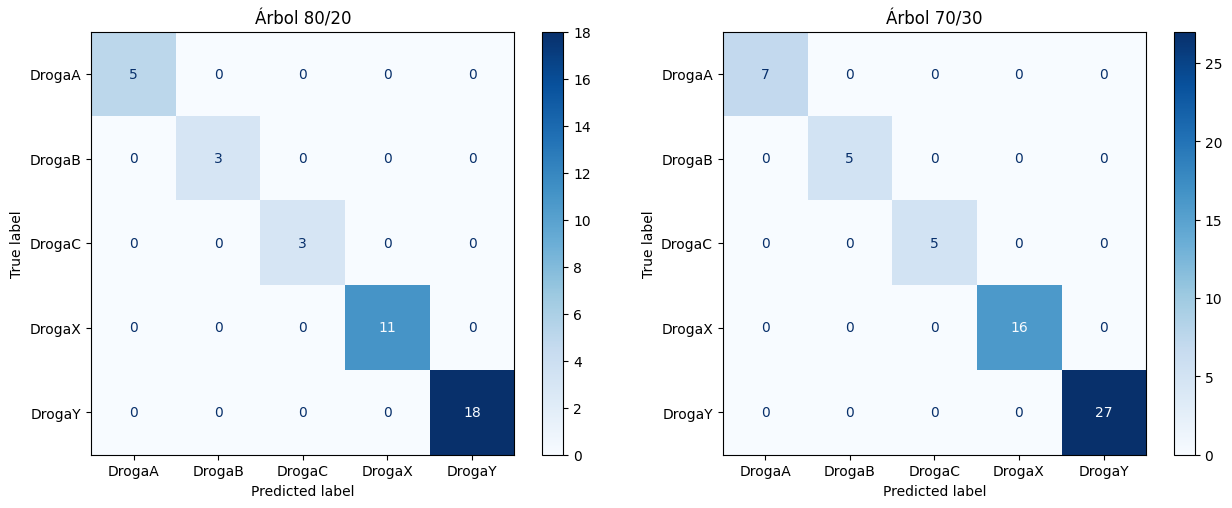

In [59]:

# Matrices de Confusión comparativas
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ConfusionMatrixDisplay.from_predictions(
    y1_test, y_pred_80, display_labels=nombres_clases, cmap=plt.cm.Blues, ax=axes[0]
)
axes[0].set_title("Árbol 80/20")

ConfusionMatrixDisplay.from_predictions(
    y2_test, y_pred_70, display_labels=nombres_clases, cmap=plt.cm.Blues, ax=axes[1]
)
axes[1].set_title("Árbol 70/30")

plt.tight_layout()
plt.show()

Se implementaron árboles de decisión sobre las particiones 80/20 y 70/30. En ambos casos, max_depth fue el hiperparámetro determinante: con profundidad 3 el árbol no logra asignar una hoja a cada una de las cinco drogas, mientras que con profundidad 4 clasifica correctamente todas las observaciones de test. La validación cruzada sobre el conjunto de entrenamiento (accuracy promedio 0,987 ± 0,016 en el 80/20) confirma que este desempeño no se debe a sobreajuste. Una vez fijada la profundidad, min_samples_leaf y min_samples_split no modificaron los resultados.

El análisis de poda mostró en ambas particiones el mismo comportamiento: cualquier valor de ccp_alpha mayor a 0 reduce el árbol a 4 hojas y agrupa DrogaC con DrogaX, por lo que DrogaC deja de predecirse. Por ello se mantuvo el árbol sin podar (ccp_alpha = 0). El modelo final es un árbol simple (profundidad 4, 6 hojas) cuyas reglas, basadas principalmente en Na_a_K, BP y Edad, separan las clases de forma prácticamente determinística.

### **Punto 5 - Bayes Ingenuo:**

 Gaussian Naïve Bayes (GaussianNB)

#### Conjunto 80/20:

In [60]:
clf_GNB_80 = GaussianNB()
clf_GNB_80.fit(X1_train, y1_train)
pred_GNB_80 = clf_GNB_80.predict(X1_test)

# Métricas 80/20
acc_GNB_80 = accuracy_score(y1_test, pred_GNB_80)
prec_GNB_80 = precision_score(y1_test, pred_GNB_80, average='macro', zero_division=0)
rec_GNB_80 = recall_score(y1_test, pred_GNB_80, average='macro', zero_division=0)

#### Conjunto 70/30:

In [61]:
clf_GNB_70 = GaussianNB()
clf_GNB_70.fit(X2_train, y2_train)
pred_GNB_70 = clf_GNB_70.predict(X2_test)

# Métricas 70/30
acc_GNB_70 = accuracy_score(y2_test, pred_GNB_70)
prec_GNB_70 = precision_score(y2_test, pred_GNB_70, average='macro', zero_division=0)
rec_GNB_70 = recall_score(y2_test, pred_GNB_70, average='macro', zero_division=0)

 Matrices de Confusión lado a lado

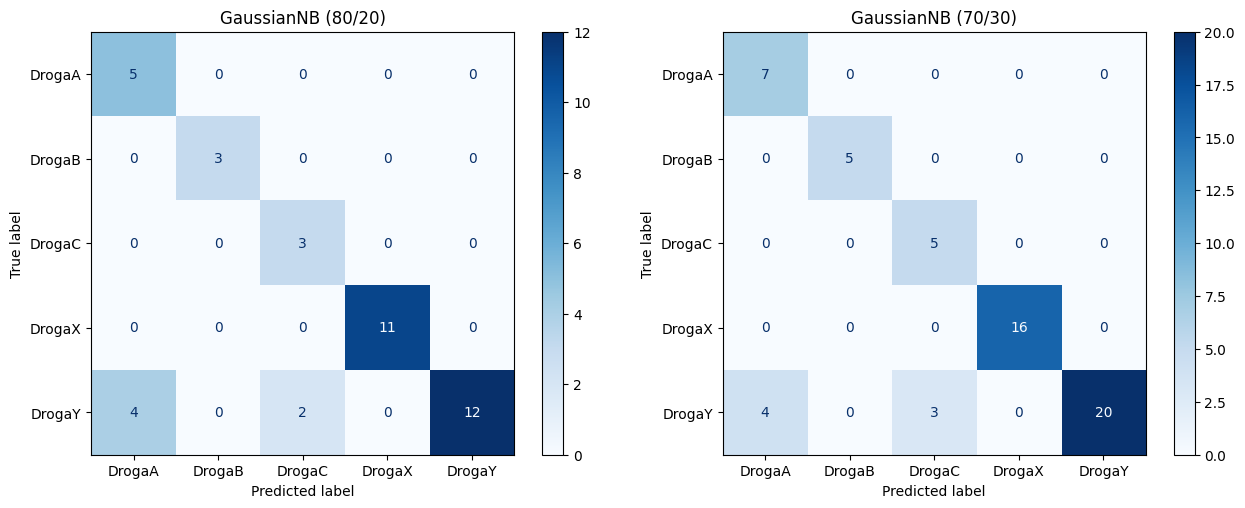

In [62]:
# Matrices de Confusión lado a lado
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay.from_predictions(y1_test, pred_GNB_80, display_labels=nombres_clases, cmap=plt.cm.Blues, ax=axes[0])
axes[0].set_title("GaussianNB (80/20)")

ConfusionMatrixDisplay.from_predictions(y2_test, pred_GNB_70, display_labels=nombres_clases, cmap=plt.cm.Blues, ax=axes[1])
axes[1].set_title("GaussianNB (70/30)")
plt.tight_layout()
plt.show()

GaussianNB clasifica correctamente todas las observaciones de DrogaA, DrogaB, DrogaC y DrogaX en ambas particiones. Todos sus errores se concentran en DrogaY: 6 de 18 pacientes en el 80/20 y 7 de 27 en el 70/30 son clasificados como DrogaA o DrogaC. Esto se debe a que el modelo representa Na_a_K con una distribución normal por clase, y DrogaY presenta un rango muy amplio de valores (de 15 a más de 30), por lo que la gaussiana no captura el umbral nítido que separa esta clase. En los pacientes de DrogaY con Na_a_K cercano a ese umbral, el resto de las variables (presión arterial, edad, colesterol) termina inclinando la predicción hacia otra droga.

#### Categorical Naïve Bayes (CategoricalNB)

In [63]:
# Columnas continuas a discretizar
cols_continuas = ['Edad', 'Na_a_K']
cols_predictoras_disc = ['Edad_disc', 'Sexo_cod', 'BP_cod', 'Colesterol_cod', 'Na_a_K_disc']

In [64]:
# --- Partición 80/20 ---
farmac1_train_3, farmac1_test_3 = discretizar(farmac1_train, farmac1_test, cols_continuas, 3)
farmac1_train_5, farmac1_test_5 = discretizar(farmac1_train, farmac1_test, cols_continuas, 5)

X1_train_3, y1_train_3 = farmac1_train_3[cols_predictoras_disc], farmac1_train_3['Droga_cod']
X1_test_3,  y1_test_3  = farmac1_test_3[cols_predictoras_disc],  farmac1_test_3['Droga_cod']

X1_train_5, y1_train_5 = farmac1_train_5[cols_predictoras_disc], farmac1_train_5['Droga_cod']
X1_test_5,  y1_test_5  = farmac1_test_5[cols_predictoras_disc],  farmac1_test_5['Droga_cod']


# CategoricalNB - Entrenamiento y Evaluación en 80/20

# 3 bins
clf_MNB_80_3 = CategoricalNB()
clf_MNB_80_3.fit(X1_train_3, y1_train_3)
pred_MNB_80_3 = clf_MNB_80_3.predict(X1_test_3)

acc_MNB_80_3 = accuracy_score(y1_test_3, pred_MNB_80_3)
prec_MNB_80_3 = precision_score(y1_test_3, pred_MNB_80_3, average='macro', zero_division=0)
rec_MNB_80_3 = recall_score(y1_test_3, pred_MNB_80_3, average='macro', zero_division=0)

# 5 bins
clf_MNB_80_5 = CategoricalNB()
clf_MNB_80_5.fit(X1_train_5, y1_train_5)
pred_MNB_80_5 = clf_MNB_80_5.predict(X1_test_5)

acc_MNB_80_5 = accuracy_score(y1_test_5, pred_MNB_80_5)
prec_MNB_80_5 = precision_score(y1_test_5, pred_MNB_80_5, average='macro', zero_division=0)
rec_MNB_80_5 = recall_score(y1_test_5, pred_MNB_80_5, average='macro', zero_division=0)

In [65]:
# --- Partición 70/30 ---
farmac2_train_3, farmac2_test_3 = discretizar(farmac2_train, farmac2_test, cols_continuas, 3)
farmac2_train_5, farmac2_test_5 = discretizar(farmac2_train, farmac2_test, cols_continuas, 5)

X2_train_3, y2_train_3 = farmac2_train_3[cols_predictoras_disc], farmac2_train_3['Droga_cod']
X2_test_3,  y2_test_3  = farmac2_test_3[cols_predictoras_disc],  farmac2_test_3['Droga_cod']

X2_train_5, y2_train_5 = farmac2_train_5[cols_predictoras_disc], farmac2_train_5['Droga_cod']
X2_test_5,  y2_test_5  = farmac2_test_5[cols_predictoras_disc],  farmac2_test_5['Droga_cod']

# CategoricalNB - Entrenamiento y Evaluación en 70/30

# 3 bins
clf_MNB_70_3 = CategoricalNB()
clf_MNB_70_3.fit(X2_train_3, y2_train_3)
pred_MNB_70_3 = clf_MNB_70_3.predict(X2_test_3)

acc_MNB_70_3 = accuracy_score(y2_test_3, pred_MNB_70_3)
prec_MNB_70_3 = precision_score(y2_test_3, pred_MNB_70_3, average='macro', zero_division=0)
rec_MNB_70_3 = recall_score(y2_test_3, pred_MNB_70_3, average='macro', zero_division=0)

# 5 bins
clf_MNB_70_5 = CategoricalNB()
clf_MNB_70_5.fit(X2_train_5, y2_train_5)
pred_MNB_70_5 = clf_MNB_70_5.predict(X2_test_5)

acc_MNB_70_5 = accuracy_score(y2_test_5, pred_MNB_70_5)
prec_MNB_70_5 = precision_score(y2_test_5, pred_MNB_70_5, average='macro', zero_division=0)
rec_MNB_70_5 = recall_score(y2_test_5, pred_MNB_70_5, average='macro', zero_division=0)

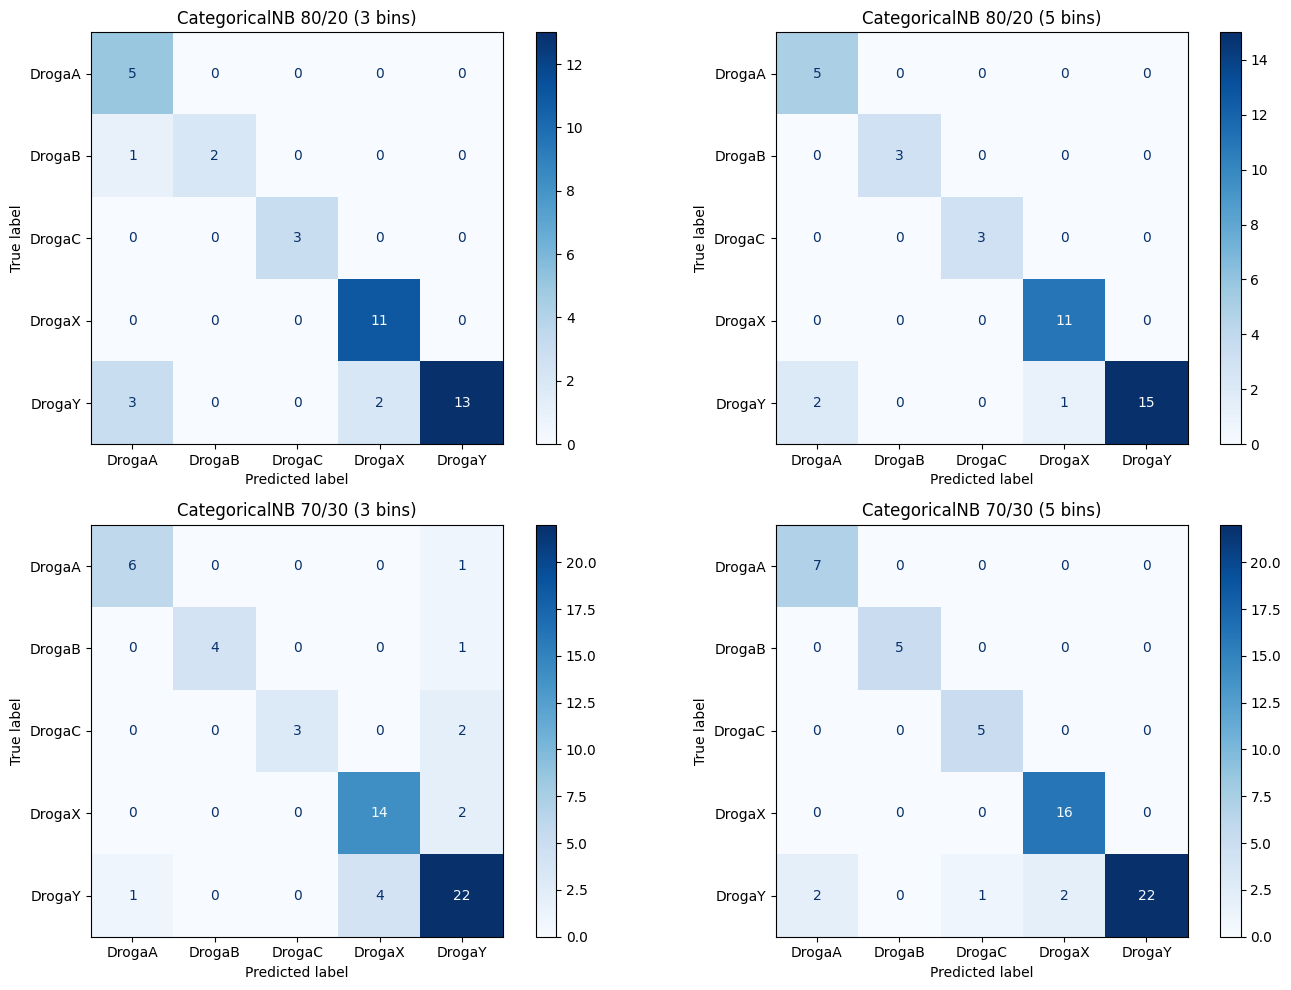

In [66]:
# Matrices de Confusión de CategoricalNB
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

ConfusionMatrixDisplay.from_predictions(y1_test_3, pred_MNB_80_3, display_labels=nombres_clases, cmap=plt.cm.Blues, ax=axes[0, 0])
axes[0, 0].set_title("CategoricalNB 80/20 (3 bins)")

ConfusionMatrixDisplay.from_predictions(y1_test_5, pred_MNB_80_5, display_labels=nombres_clases, cmap=plt.cm.Blues, ax=axes[0, 1])
axes[0, 1].set_title("CategoricalNB 80/20 (5 bins)")

ConfusionMatrixDisplay.from_predictions(y2_test_3, pred_MNB_70_3, display_labels=nombres_clases, cmap=plt.cm.Blues, ax=axes[1, 0])
axes[1, 0].set_title("CategoricalNB 70/30 (3 bins)")

ConfusionMatrixDisplay.from_predictions(y2_test_5, pred_MNB_70_5, display_labels=nombres_clases, cmap=plt.cm.Blues, ax=axes[1, 1])
axes[1, 1].set_title("CategoricalNB 70/30 (5 bins)")

plt.tight_layout()
plt.show()

Con 5 intervalos, CategoricalNB mejora claramente respecto de 3: en el 80/20 comete 3 errores (frente a 7 con 3 intervalos) y en el 70/30, 5 (frente a 11). Al dividir Na_a_K en más intervalos, alguno de los cortes queda cerca del umbral que separa DrogaY del resto (≈14,8), mientras que con 3 intervalos uno de ellos mezcla pacientes de DrogaY con pacientes de otras drogas. Con 5 intervalos, al igual que en GaussianNB, todos los errores corresponden a pacientes de DrogaY clasificados como otra droga.

#### CONCLUSIÓN:

In [67]:
res_bayes = pd.DataFrame({
    'Modelo': [
        'GaussianNB 80/20',
        'GaussianNB 70/30',
        'CategoricalNB 80/20 - 3 bins',
        'CategoricalNB 80/20 - 5 bins',
        'CategoricalNB 70/30 - 3 bins',
        'CategoricalNB 70/30 - 5 bins'
    ],
    'Accuracy': [acc_GNB_80, acc_GNB_70, acc_MNB_80_3, acc_MNB_80_5, acc_MNB_70_3, acc_MNB_70_5],
    'Precision Macro': [prec_GNB_80, prec_GNB_70, prec_MNB_80_3, prec_MNB_80_5, prec_MNB_70_3, prec_MNB_70_5],
    'Recall Macro': [rec_GNB_80, rec_GNB_70, rec_MNB_80_3, rec_MNB_80_5, rec_MNB_70_3, rec_MNB_70_5]
})

display(res_bayes.round(3))

,Modelo,Accuracy,Precision Macro,Recall Macro
0,GaussianNB 80/20,0.850,0.831,0.933
1,GaussianNB 70/30,0.883,0.852,0.948
2,CategoricalNB 80/20 - 3 bins,0.850,0.880,0.878
3,CategoricalNB 80/20 - 5 bins,0.925,0.926,0.967
4,CategoricalNB 70/30 - 3 bins,0.817,0.884,0.789
5,CategoricalNB 70/30 - 5 bins,0.917,0.900,0.963


Para aplicar Naive Bayes sobre datos discretizados se utilizó CategoricalNB, que trata cada intervalo como una categoría, en lugar de MultinomialNB, que interpreta los valores como conteos y no es adecuado para variables categóricas u ordinales.

El mejor modelo bayesiano fue CategoricalNB con 5 intervalos, con Accuracy de 0,925 y 0,917, y Recall macro de 0,967 y 0,963 en las particiones 80/20 y 70/30, respectivamente. Supera a GaussianNB, porque la discretización por cuantiles permite representar el umbral de Na_a_K sin suponer una distribución normal. Con 3 intervalos el desempeño es inferior, ya que los cortes no se alinean con ese umbral.

En todos los modelos bayesianos los errores se concentran en DrogaY. Esto refleja una limitación del supuesto de independencia: el modelo combina la evidencia de todas las variables de forma aditiva, cuando en este problema DrogaY queda determinada solo por Na_a_K. Así, en algunos pacientes, la evidencia de la presión arterial o la edad compensa la de Na_a_K y lleva a una clasificación incorrecta. El árbol de decisión, en cambio, aplica primero el corte de Na_a_K y solo después considera las demás variables.

### **Punto 6 - k-NN:**

#### Conjunto 80/20:

Selección de k:

In [68]:
# 1. Estandarización de características para 80/20
scaler_80 = StandardScaler()
X1_train_scaled = scaler_80.fit_transform(X1_train)
X1_test_scaled  = scaler_80.transform(X1_test)

# 2. Búsqueda de k y métrica de distancia
vecinos = [1, 3, 5, 7, 9]
metricas = ['euclidean', 'manhattan']
resultados_knn_80 = []

for k in vecinos:
    for metrica in metricas:
        knn = KNeighborsClassifier(n_neighbors=k, metric=metrica)
        knn.fit(X1_train_scaled, y1_train)
        pred = knn.predict(X1_test_scaled)

        resultados_knn_80.append({
            'k': k,
            'metric': metrica,
            'Accuracy': round(accuracy_score(y1_test, pred), 3),
            'Precision_macro': round(precision_score(y1_test, pred, average='macro', zero_division=0), 3),
            'Recall_macro': round(recall_score(y1_test, pred, average='macro', zero_division=0), 3)
        })

df_knn_80 = pd.DataFrame(resultados_knn_80)
display(df_knn_80)

,k,metric,Accuracy,Precision_macro,Recall_macro
0,1,euclidean,0.850,0.813,0.897
1,1,manhattan,0.850,0.813,0.897
2,3,euclidean,0.900,0.886,0.956
3,3,manhattan,0.850,0.847,0.926
4,5,euclidean,0.850,0.856,0.926
5,5,manhattan,0.850,0.850,0.878
6,7,euclidean,0.775,0.793,0.746
7,7,manhattan,0.750,0.746,0.735
8,9,euclidean,0.750,0.768,0.728
9,9,manhattan,0.825,0.839,0.831


Para la partición 80/20 se selecciona k = 3 con distancia euclidiana, que obtiene el mejor desempeño (Accuracy 0,900, Precision macro 0,886, Recall macro 0,956). Valores de k mayores reducen el desempeño, porque los vecinos de las clases minoritarias quedan en minoría frente a las clases más frecuentes, y k = 1 resulta más sensible a observaciones individuales.

#### Conjunto 70/30:

Selección de k:

In [69]:
# 1. Estandarización de características para 70/30
scaler_70 = StandardScaler()
X2_train_scaled = scaler_70.fit_transform(X2_train)
X2_test_scaled  = scaler_70.transform(X2_test)

# 2. Búsqueda de k y métrica de distancia
resultados_knn_70 = []

for k in vecinos:
    for metrica in metricas:
        knn = KNeighborsClassifier(n_neighbors=k, metric=metrica)
        knn.fit(X2_train_scaled, y2_train)
        pred = knn.predict(X2_test_scaled)

        resultados_knn_70.append({
            'k': k,
            'metric': metrica,
            'Accuracy': round(accuracy_score(y2_test, pred), 3),
            'Precision_macro': round(precision_score(y2_test, pred, average='macro', zero_division=0), 3),
            'Recall_macro': round(recall_score(y2_test, pred, average='macro', zero_division=0), 3)
        })

df_knn_70 = pd.DataFrame(resultados_knn_70)
display(df_knn_70)

,k,metric,Accuracy,Precision_macro,Recall_macro
0,1,euclidean,0.850,0.831,0.853
1,1,manhattan,0.867,0.850,0.893
2,3,euclidean,0.850,0.854,0.933
3,3,manhattan,0.900,0.902,0.956
4,5,euclidean,0.783,0.763,0.807
5,5,manhattan,0.717,0.661,0.680
6,7,euclidean,0.783,0.783,0.769
7,7,manhattan,0.800,0.791,0.842
8,9,euclidean,0.700,0.644,0.624
9,9,manhattan,0.767,0.761,0.735


Para la partición 70/30 se selecciona k = 3 con distancia Manhattan, que obtiene el mejor desempeño (Accuracy 0,900, Precision macro 0,902, Recall macro 0,956). Al igual que en el 80/20, k = 3 es el valor óptimo, y el desempeño cae al aumentar la cantidad de vecinos.

#### Matriz de confusión:

In [70]:
knn_8020 = KNeighborsClassifier(n_neighbors=3, metric='euclidean')
knn_8020.fit(X1_train_scaled, y1_train)
pred_knn_80 = knn_8020.predict(X1_test_scaled)

acc_knn_80  = accuracy_score(y1_test, pred_knn_80)
prec_knn_80 = precision_score(y1_test, pred_knn_80, average='macro', zero_division=0)
rec_knn_80  = recall_score(y1_test, pred_knn_80, average='macro', zero_division=0)


best_k_70 = 3
knn_7030 = KNeighborsClassifier(n_neighbors=best_k_70, metric='manhattan')
knn_7030.fit(X2_train_scaled, y2_train)
pred_knn_70 = knn_7030.predict(X2_test_scaled)

acc_knn_70  = accuracy_score(y2_test, pred_knn_70)
prec_knn_70 = precision_score(y2_test, pred_knn_70, average='macro', zero_division=0)
rec_knn_70  = recall_score(y2_test, pred_knn_70, average='macro', zero_division=0)


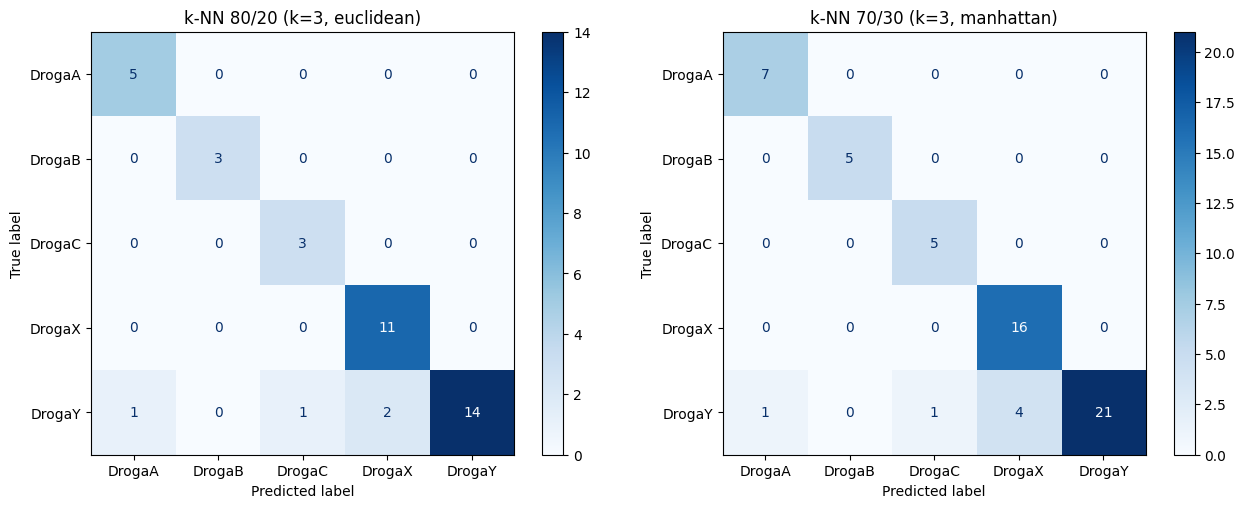

In [71]:
# Visualización de Matrices de Confusión
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ConfusionMatrixDisplay.from_predictions(
    y1_test, pred_knn_80, display_labels=nombres_clases, cmap=plt.cm.Blues, ax=axes[0]
)
axes[0].set_title(f"k-NN 80/20 (k=3, euclidean)")

ConfusionMatrixDisplay.from_predictions(
    y2_test, pred_knn_70, display_labels=nombres_clases, cmap=plt.cm.Blues, ax=axes[1]
)
axes[1].set_title(f"k-NN 70/30 (k={best_k_70}, manhattan)")

plt.tight_layout()
plt.show()

En ambas particiones, k-NN clasifica correctamente todas las observaciones de DrogaA, DrogaB, DrogaC y DrogaX. Sus errores corresponden exclusivamente a pacientes de DrogaY: 4 en el 80/20 (clasificados como DrogaA, DrogaC o DrogaX) y 6 en el 70/30 (uno como DrogaA, uno como DrogaC y cuatro como DrogaX).

Al igual que en Naive Bayes, los errores se concentran en DrogaY. k-NN calcula la distancia combinando todas las variables con el mismo peso (tras la estandarización), por lo que un paciente de DrogaY con Na_a_K cercano al umbral puede tener como vecinos más cercanos a pacientes de otras drogas con presión arterial, edad o colesterol similares.

La estandarización previa con StandardScaler es indispensable en este modelo, ya que sin ella las variables con mayor rango (Edad y Na_a_K) dominarían el cálculo de distancias.

### **Punto 7 - Comparación de modelos:**

In [72]:
# COMPARACIÓN FINAL DE MODELOS DE CLASIFICACIÓN

comparacion_modelos = pd.DataFrame({
    'Modelo': [
        'Árbol de Decisión (80/20)',
        'Árbol de Decisión (70/30)',
        'CategoricalNB (80/20)',
        'CategoricalNB (70/30)',
        'k-NN (80/20)',
        'k-NN (70/30)'
    ],
    'Accuracy': [
        accuracy_8020,
        accuracy_7030,
        acc_MNB_80_5,
        acc_MNB_70_5,
        acc_knn_80,
        acc_knn_70
    ],
    'Precision Macro': [
        precision_8020,
        precision_7030,
        prec_MNB_80_5,
        prec_MNB_70_5,
        prec_knn_80,
        prec_knn_70
    ],
    'Recall Macro': [
        recall_8020,
        recall_7030,
        rec_MNB_80_5,
        rec_MNB_70_5,
        rec_knn_80,
        rec_knn_70
    ]
})

display(comparacion_modelos.round(3))

,Modelo,Accuracy,Precision Macro,Recall Macro
0,Árbol de Decisión (80/20),1.000,1.000,1.000
1,Árbol de Decisión (70/30),1.000,1.000,1.000
2,CategoricalNB (80/20),0.925,0.926,0.967
3,CategoricalNB (70/30),0.917,0.900,0.963
4,k-NN (80/20),0.900,0.886,0.956
5,k-NN (70/30),0.900,0.902,0.956


**Análisis comparativo de los algoritmos**

- Árbol de decisión (max_depth = 4, sin poda): clasificó correctamente todas las observaciones de test en ambas particiones (Accuracy, Precision y Recall macro = 1). La validación cruzada (0,987 ± 0,016) confirma que este resultado no se debe a sobreajuste. Su estructura jerárquica coincide con la del problema: primero separa DrogaY mediante Na_a_K y luego distingue el resto según la presión arterial, la edad y el colesterol.
- Naive Bayes (CategoricalNB, 5 intervalos): fue el segundo mejor modelo (Accuracy 0,925 y 0,917; Recall macro 0,967 y 0,963). Sus errores se concentran en DrogaY, por el supuesto de independencia: combina la evidencia de todas las variables, cuando DrogaY queda determinada solo por Na_a_K.
- k-NN (k = 3): obtuvo el desempeño más bajo de los tres (Accuracy 0,900 en ambas particiones), con errores también concentrados en DrogaY. Al calcular distancias con todas las variables con igual peso, no puede priorizar Na_a_K como hace el árbol.

Los tres modelos clasifican sin errores las drogas A, B, C y X, y las diferencias entre ellos se explican por cómo resuelven los pacientes de DrogaY cercanos al umbral de Na_a_K.

**Selección y Justificación del Modelo Final**

El modelo más adecuado para este problema es el árbol de decisión. Es el que obtiene las mejores métricas en ambas particiones y, además, el más interpretable: sus reglas (por ejemplo, “si Na_a_K > 14,8, entonces DrogaY”) pueden ser leídas y verificadas directamente por un profesional de la salud. A diferencia de lo que suele ocurrir, en este caso no existe un compromiso entre desempeño e interpretabilidad: el modelo más simple de interpretar es también el más preciso, porque la estructura del problema, basada en umbrales sobre pocas variables, coincide con la forma en que el árbol toma decisiones.

### Conclusiones finales

Parte A – Regresión. El árbol de decisión estimó Profit con un MAE de 2.105,84 (80/20) y 1.569,89 (70/30), menos del 2% del Profit medio. RyD_Spend fue la variable dominante en ambos árboles, en línea con su correlación casi perfecta con Profit. El tratamiento de las observaciones anómalas, justificado comparando su Profit con el de empresas de inversión similar, fortaleció las relaciones entre variables. La gran diferencia entre RMSE y MAE se explica por una única observación anómala presente en ambos conjuntos de test, lo que muestra la importancia de elegir una métrica robusta para comparar modelos.

Parte B – Clasificación. El árbol de decisión fue el mejor modelo, con clasificación perfecta en ambas particiones, seguido por CategoricalNB y k-NN. El análisis exploratorio ya anticipaba este resultado: Na_a_K separa DrogaY del resto mediante un umbral, y las demás drogas se distinguen por la presión arterial, la edad y el colesterol. Esta estructura de reglas jerárquicas es exactamente la que construye un árbol. Por eso Naive Bayes y k-NN, que combinan todas las variables a la vez, concentran sus errores en los pacientes de DrogaY cercanos a ese umbral. Dado el desbalance de clases, las métricas macro fueron más informativas que la Accuracy para evaluar el desempeño sobre las drogas minoritarias.